## Imports

In [3]:
import os
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
# %run common_imports.py

# Select the model family before loading data. A single-direction family
# omits trial_type because that predictor is constant within its cohort.
MODEL_GROUP_CONFIGS = {
    "current_all_terms": {
        "sample_mode": "masked", "trial_type_selection": "both",
        "terms": ("trial_type", "position", "progress", "translation", "turning", "limb"),
    },
    "unmasked_all_terms": {
        "sample_mode": "unmasked", "trial_type_selection": "both",
        "terms": ("trial_type", "position", "progress", "translation", "turning", "limb"),
    },
    "unmasked_all_terms_graph_v1": {
        "sample_mode": "unmasked", "trial_type_selection": "both",
        "terms": ("trial_type", "position", "progress", "translation", "turning", "limb"),
    },
    "unmasked_outbound_terms": {
        "sample_mode": "unmasked", "trial_type_selection": "outbound",
        "terms": ("position", "progress", "translation", "turning", "limb"),
    },
    "unmasked_inbound_terms": {
        "sample_mode": "unmasked", "trial_type_selection": "inbound",
        "terms": ("position", "progress", "translation", "turning", "limb"),
    },
    "progress_position_translation": {
        "sample_mode": "masked", "trial_type_selection": "both",
        "terms": ("progress", "position", "translation"),
    },
}
MODEL_GROUP_NAME = "unmasked_all_terms_graph_v1"
if MODEL_GROUP_NAME not in MODEL_GROUP_CONFIGS:
    raise KeyError(f"Unknown model group: {MODEL_GROUP_NAME}")
MODEL_GROUP_CONFIG = MODEL_GROUP_CONFIGS[MODEL_GROUP_NAME]
ENCODING_SAMPLE_MODE = MODEL_GROUP_CONFIG["sample_mode"]
ENCODING_TRIAL_TYPE_SELECTION = MODEL_GROUP_CONFIG["trial_type_selection"]

# Behavioral analyses can use their own sample mode.
# Choose "masked" for run-zone samples with renormalized progress, or
# "unmasked" for every outbound/inbound sample with full-trial progress.
BEHAVIORAL_ANALYSIS_MODE = "unmasked"
BEHAVIORAL_TRIAL_TYPE_SELECTION = ENCODING_TRIAL_TYPE_SELECTION
BEHAVIORAL_ANALYSIS_MODES = {"masked", "unmasked"}
if BEHAVIORAL_ANALYSIS_MODE not in BEHAVIORAL_ANALYSIS_MODES:
    raise ValueError(
        f"BEHAVIORAL_ANALYSIS_MODE must be one of "
        f"{sorted(BEHAVIORAL_ANALYSIS_MODES)}"
    )

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir("..")

PROJECT_ROOT = Path.cwd().resolve()
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
for path in [PROJECT_ROOT, NOTEBOOKS_DIR]:
    path_str = str(path)
    if path_str not in sys.path:
        sys.path.insert(0, path_str)

%config InlineBackend.figure_format = 'retina'
# ---- Figure style: match TCM_1_figures.ipynb / unit_tuning.ipynb ----
OKABE_ITO = [
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#009E73",  # bluish green
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#CC79A7",  # reddish purple
    "#F0E442",  # yellow
    "#000000",  # black
]

sns.set_context("paper", font_scale=0.8)
sns.set_palette(OKABE_ITO)
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
colors = OKABE_ITO


%reload_ext autoreload
%autoreload 2
pd.options.display.max_columns = 50
pd.set_option('display.float_format', lambda x: '%.9f' % x)

In [4]:
%matplotlib qt
sns.set_context("talk")
import importlib
import ipywidgets as widgets

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import chi2
import spyglass.position.v1 as sgp
import spyglass.linearization.v1 as sgpl
from spyglass.position import PositionOutput
from spyglass.utils.nwb_helper_fn import get_nwb_copy_filename

try:
    import encoding_utils as _encoding_utils
    from encoding_utils import *
    from graph_distance import *
    from spike_visualisation import *
    from movement_features import *
    from movement_encoding import *
    from movement_model_runner import *
    import movement_model_results as _movement_model_results
    importlib.reload(_movement_model_results)
    from movement_model_results import *
    from movement_visualization import *
except ModuleNotFoundError:
    import notebooks.encoding_utils as _encoding_utils
    from notebooks.encoding_utils import *
    from notebooks.graph_distance import *
    from notebooks.spike_visualisation import *
    from notebooks.movement_features import *
    from notebooks.movement_encoding import *
    from notebooks.movement_model_runner import *
    import notebooks.movement_model_results as _movement_model_results
    importlib.reload(_movement_model_results)
    from notebooks.movement_model_results import *
    from notebooks.movement_visualization import *


[2026-10-05 16:57:50,645][INFO]: DataJoint 0.14.9 connected to anirudh@172.16.102.154:3306


## Load data

In [5]:
base_dir = CONFIG["base_dir"]
BIN_SIZE = CONFIG["bin_size"]

data = load_and_prepare_data(
    sample_mode=ENCODING_SAMPLE_MODE,
    trial_type_selection=ENCODING_TRIAL_TYPE_SELECTION,
)
cov_df_correct = data["cov_df_correct"] #covariate dataframe, data from all correct trials
spike_counts_correct = data["spike_counts_correct"]
cov_df_common        = data["cov_df_common"] # model covariates after the selected sample mode and common filters
cov_df_out_common    = data["cov_df_out_common"] # only outbound trials, for choice analysis
spike_counts_common  = data["spike_counts_common"]
spike_counts_out_common = data["spike_counts_out_common"]
unit_ids             = data["unit_ids"]
bin_centers          = data["bin_centers"]
sp                   = data["scaling_params"]
pos_min_val, pos_max_val   = sp["pos_min"], sp["pos_max"]
speed_min_val, speed_max_val = sp["speed_min"], sp["speed_max"]

# trialized position : used by W-track visualization
trialized_position = pd.read_csv(CONFIG["trialized_position"], index_col="time")

print(f"Encoding samples: {ENCODING_SAMPLE_MODE}; trial type: {ENCODING_TRIAL_TYPE_SELECTION}")
print(f"cov_df_common: {len(cov_df_common):,} bins")
print(f"cov_df_out_common: {len(cov_df_out_common):,} bins (outbound)")

# model registry 
registry = build_model_registry()

Encoding samples: unmasked; trial type: both
cov_df_common: 704,906 bins
cov_df_out_common: 304,845 bins (outbound)


## Derive movement features

Features are calculated at the original video sampling times. DLC samples are aligned to the existing position table by `epoch + video_frame_ind`. Paw trajectories are transformed into the body frame for geometry, while world-coordinate velocities are used to subtract rigid body translation and rotation for relative paw vigor. RF gait phase is defined only between validated touchdowns using the visually checked detector settings below. Lateral coordination phase is independently defined between successive prominent peaks of the smoothed diagonal-opposition signal, with a required intervening trough.

In [9]:
# Session and DLC inputs used to construct the existing Wilbur position table.
SESSION_NAME = "wilbur20210512"
NWB_COPY_FILE_NAME = get_nwb_copy_filename(f"{SESSION_NAME}.nwb")
TRACK_GRAPH_NAME = CONFIG["wtrack_name"]
CENTER_WELL_NODE = 0
TRACK_SEGMENT_ORDER = (3, 1, 0, 2, 4)
PAW_PREFIXES = DEFAULT_PAW_PREFIXES.copy()
BODY_FRAME_SMOOTHING_S = 0.1
PAW_KINEMATICS_SMOOTHING_S = 0.1
MOVEMENT_DIRECTION_SMOOTHING_S = 0.25
MOVEMENT_DIRECTION_MIN_SPEED_CM_S = 5.0
GAIT_REFERENCE_PAW = "forepawR"
GAIT_SMOOTHING_S = 0.1
GAIT_PEAK_PROMINENCE_CM_S = 10.0
GAIT_PEAK_DISTANCE_SAMPLES = 2
GAIT_SWING_BOUNDARY_CM_S = 15.0
GAIT_MIN_BODY_SPEED_CM_S = 5.0
GAIT_MIN_STANCE_SAMPLES = 2
GAIT_MIN_STRIDE_S = 0.18
GAIT_MAX_STRIDE_S = 0.80
LATERAL_PHASE_SMOOTHING_S = 0.1
LATERAL_PHASE_PEAK_PROMINENCE_CM = 0.2
LATERAL_PHASE_MIN_BODY_SPEED_CM_S = 5.0
LATERAL_PHASE_MIN_CYCLE_S = 0.18
LATERAL_PHASE_MAX_CYCLE_S = 0.80

position_epochs = sorted(
    trialized_position["epoch"].dropna().astype(int).unique().tolist()
)
print(f"Session: {NWB_COPY_FILE_NAME}")
print(f"Epochs: {position_epochs}")
print(f"Track graph: {TRACK_GRAPH_NAME}")
print(f"Center-well node: {CENTER_WELL_NODE}")
print(f"Track-segment order: {TRACK_SEGMENT_ORDER}")
print(f"Body-frame smoothing: {BODY_FRAME_SMOOTHING_S:.3f} s")
print(f"Paw-kinematics smoothing: {PAW_KINEMATICS_SMOOTHING_S:.3f} s")
print(f"Movement-direction smoothing: {MOVEMENT_DIRECTION_SMOOTHING_S:.3f} s")
print(f"Movement-direction minimum speed: {MOVEMENT_DIRECTION_MIN_SPEED_CM_S:.1f} cm/s")
print(
    f"Gait: {GAIT_REFERENCE_PAW}, strides "
    f"{GAIT_MIN_STRIDE_S:.2f}–{GAIT_MAX_STRIDE_S:.2f} s, "
    f"minimum stance {GAIT_MIN_STANCE_SAMPLES} samples"
)
print(
    f"Lateral phase: diagonal signal, "
    f"prominence ≥{LATERAL_PHASE_PEAK_PROMINENCE_CM:.1f} cm, "
    f"cycles {LATERAL_PHASE_MIN_CYCLE_S:.2f}–"
    f"{LATERAL_PHASE_MAX_CYCLE_S:.2f} s"
)

Session: wilbur20210512_.nwb
Epochs: [2, 4, 6, 8]
Track graph: Wtrack_center0_wilbur20210512
Center-well node: 0
Track-segment order: (3, 1, 0, 2, 4)
Body-frame smoothing: 0.100 s
Paw-kinematics smoothing: 0.100 s
Movement-direction smoothing: 0.250 s
Movement-direction minimum speed: 5.0 cm/s
Gait: forepawR, strides 0.18–0.80 s, minimum stance 2 samples
Lateral phase: diagonal signal, prominence ≥0.2 cm, cycles 0.18–0.80 s


In [10]:
# Match the paw traces to the exact DLC cohort used by PositionOutput.DLCPosV1.
pos_rows = (
    PositionOutput.DLCPosV1
    & {"nwb_file_name": NWB_COPY_FILE_NAME}
    & [{"epoch": epoch} for epoch in position_epochs]
).fetch(as_dict=True)

pose_by_epoch = {}
for epoch in position_epochs:
    epoch_rows = [row for row in pos_rows if int(row["epoch"]) == epoch]
    if len(epoch_rows) != 1:
        raise ValueError(
            f"Expected one DLCPosV1 row for epoch {epoch}; found {len(epoch_rows)}"
        )
    pos_row = epoch_rows[0]
    base_pose_key = {
        key: pos_row[key]
        for key in [
            "nwb_file_name",
            "epoch",
            "video_file_num",
            "project_name",
            "dlc_model_name",
            "dlc_model_params_name",
        ]
    }
    cohort_key = {
        **base_pose_key,
        "dlc_si_cohort_selection_name": pos_row["dlc_si_cohort_centroid"],
    }
    paw_si_params = (
        sgp.DLCSmoothInterpCohortSelection & cohort_key
    ).fetch1("bodyparts_params_dict")

    epoch_pose = {}
    for bodypart in PAW_PREFIXES:
        if bodypart not in paw_si_params:
            raise KeyError(f"{bodypart} is absent from the epoch {epoch} centroid cohort")
        pose_key = {
            **base_pose_key,
            "bodypart": bodypart,
            "dlc_si_params_name": paw_si_params[bodypart],
        }
        epoch_pose[bodypart] = (
            sgp.DLCSmoothInterp & pose_key
        ).fetch1_dataframe()

    pose_by_epoch[epoch] = epoch_pose

track_graph = (
    sgpl.TrackGraph & {"track_graph_name": TRACK_GRAPH_NAME}
).fetch1()

In [11]:
# Reload the source table so this cell is safe to rerun after features were added.
trialized_position_raw = pd.read_csv(
    CONFIG["trialized_position"], index_col="time"
)
movement_features, gait_events, lateral_phase_events = derive_movement_features(
    trialized_position_raw,
    pose_by_epoch=pose_by_epoch,
    node_positions=track_graph["node_positions"],
    linear_edge_order=track_graph["linear_edge_order"],
    paw_prefixes=PAW_PREFIXES,
    body_frame_smoothing_s=BODY_FRAME_SMOOTHING_S,
    paw_kinematics_smoothing_s=PAW_KINEMATICS_SMOOTHING_S,
    movement_direction_smoothing_s=MOVEMENT_DIRECTION_SMOOTHING_S,
    movement_direction_min_speed_cm_s=MOVEMENT_DIRECTION_MIN_SPEED_CM_S,
    center_well_node=CENTER_WELL_NODE,
    track_segment_order=TRACK_SEGMENT_ORDER,
    gait_reference_paw=GAIT_REFERENCE_PAW,
    gait_smoothing_s=GAIT_SMOOTHING_S,
    gait_peak_prominence_cm_s=GAIT_PEAK_PROMINENCE_CM_S,
    gait_peak_distance_samples=GAIT_PEAK_DISTANCE_SAMPLES,
    gait_swing_boundary_cm_s=GAIT_SWING_BOUNDARY_CM_S,
    gait_min_body_speed_cm_s=GAIT_MIN_BODY_SPEED_CM_S,
    gait_min_stance_samples=GAIT_MIN_STANCE_SAMPLES,
    gait_min_stride_s=GAIT_MIN_STRIDE_S,
    gait_max_stride_s=GAIT_MAX_STRIDE_S,
    lateral_phase_smoothing_s=LATERAL_PHASE_SMOOTHING_S,
    lateral_phase_peak_prominence_cm=LATERAL_PHASE_PEAK_PROMINENCE_CM,
    lateral_phase_min_body_speed_cm_s=LATERAL_PHASE_MIN_BODY_SPEED_CM_S,
    lateral_phase_min_cycle_s=LATERAL_PHASE_MIN_CYCLE_S,
    lateral_phase_max_cycle_s=LATERAL_PHASE_MAX_CYCLE_S,
    return_gait_events=True,
    return_lateral_phase_events=True,
)
trialized_position = trialized_position_raw.join(movement_features)

# Existing task and position columns must remain byte-for-byte equivalent.
pd.testing.assert_frame_equal(
    trialized_position.loc[:, trialized_position_raw.columns],
    trialized_position_raw,
    check_exact=True,
)
# Match the graph-distance progress recomputed by load_and_prepare_data for
# behavioral plots, while retaining the original source table for feature derivation.
trialized_position = recompute_graph_progress(
    trialized_position,
    node_positions=WILBUR_WTRACK_CENTER0_NODE_POSITIONS,
    linear_edge_order=WILBUR_WTRACK_CENTER0_LINEAR_EDGE_ORDER,
    edge_spacing=WTRACK_CENTER0_LINEAR_EDGE_SPACING,
    segment_order=WILBUR_WTRACK_CENTER0_TRACK_SEGMENT_ORDER,
)

PREDICTOR_GROUPS = build_movement_predictor_groups(PAW_PREFIXES)
PENALTY_BANDS = build_movement_penalty_bands(PREDICTOR_GROUPS)
COMPACT_LIMB_COLUMNS = list(PREDICTOR_GROUPS["limb"])

MOVEMENT_FEATURE_GROUPS = {
    "translation": [
        "speed",
        "tangential_acceleration_cm_s2",
    ],
    "turning": [
        "body_angular_velocity_rad_s",
    ],
    "limb": [
        *COMPACT_LIMB_COLUMNS,
    ],
}

# Stored separately for inspection and excluded from models.
AUXILIARY_FEATURES = [
    "body_orientation_rad",
    "reference_paw_world_speed_cm_s",
    "lateral_coordination_signal_cm",
    "lateral_coordination_signal_smoothed_cm",
    # Excluded from MODEL_SOURCE_COLUMNS: undefined outside accepted
    # stride/cycle intervals (24.1%/9.9% of frames); gating the shared
    # completeness mask on these drops most otherwise-valid bins.
    "gait_phase_sin",
    "gait_phase_cos",
    "lateral_phase_sin",
    "lateral_phase_cos",
]
DISPLAY_FEATURES = []
MODEL_FEATURE_COLUMNS = [
    column
    for columns in MOVEMENT_FEATURE_GROUPS.values()
    for column in columns
]
MODEL_SOURCE_COLUMNS = list(MODEL_FEATURE_COLUMNS)
SPLINE_CONFIG = movement_spline_config(PAW_PREFIXES)
MOVEMENT_MODEL_REGISTRY = build_movement_model_registry(PREDICTOR_GROUPS)
INNER_CV_CONFIG = {
    "n_splits": 3,
    "seed": 42,
    "lower_log10": -8.0,
    "upper_log10": 2.0,
    "log10_step": 2.0,
    "edge_expansion_log10": 2.0,
    "max_grid_expansions": 10,
}
BANDED_OPTIMIZER_CONFIG = {
    "max_iter": 20,
    "max_evaluations": 30,
    "gtol": 1e-4,
    "ftol": 1e-9,
}

print(
    f"Retained gait events: {len(gait_events):,}; "
    f"accepted strides: "
    f"{gait_events['accepted_stride_to_next'].sum():,}"
)
print(
    f"Retained lateral peaks: {len(lateral_phase_events):,}; "
    f"accepted cycles: "
    f"{lateral_phase_events['accepted_cycle_to_next'].sum():,}"
)
movement_features.notna().mean().rename("fraction_valid").to_frame()

Retained gait events: 3,835; accepted strides: 2,651
Retained lateral peaks: 1,801; accepted cycles: 922


,fraction_valid
tangential_acceleration_cm_s2,0.997980115
body_orientation_rad,0.795119121
movement_relative_body_orientation_rad,0.338359051
track_relative_orientation_rad,0.705310595
track_relative_orientation_deg,0.705310595
body_angular_velocity_rad_s,0.789447738
forepaw_l_ap_cm,0.795119121
forepaw_l_lateral_cm,0.795119121
forepaw_l_ap_velocity_cm_s,0.789883998
forepaw_l_lateral_velocity_cm_s,0.789883998


## Add movement features to the encoding tables

Interpolation is performed separately within each epoch and finite tracking run. Models compared across the three movement groups use one complete-case mask, keeping their time bins and spike counts identical. The limb group uses compact gait-phase, relative-vigor, and body-frame geometry predictors; raw paw coordinates and distances are retained only for inspection and visualization. Spline transforms are fitted on each outer-training split, and the two sine/cosine gait-phase components enter linearly.

The encoding model uses six ridge-penalty bands: trial type, position, progress, translation, turning, and limb. Within each neuron and outer fold, the full model selects the six penalties. All reduced, individual-term, and shuffled/ablated models reuse the applicable full-model penalties and refit coefficients.

In [12]:
source_epochs = trialized_position_raw["epoch"].to_numpy()
cov_df_correct = interpolate_features_to_bins(
    movement_features, source_epochs, cov_df_correct
)
cov_df_common = interpolate_features_to_bins(
    movement_features, source_epochs, cov_df_common
)
cov_df_out_common = interpolate_features_to_bins(
    movement_features, source_epochs, cov_df_out_common
)

common_before = len(cov_df_common)
common_valid = cov_df_common[MODEL_SOURCE_COLUMNS].notna().all(axis=1)
cov_df_common = cov_df_common.loc[common_valid].copy()
spike_counts_common = spike_counts_common[:, common_valid.to_numpy()]

outbound_before = len(cov_df_out_common)
outbound_valid = cov_df_out_common[MODEL_SOURCE_COLUMNS].notna().all(axis=1)
cov_df_out_common = cov_df_out_common.loc[outbound_valid].copy()
spike_counts_out_common = (
    spike_counts_out_common[:, outbound_valid.to_numpy()]
)

# Keep the returned data bundle synchronized with the notebook variables.
data.update({
    "cov_df_correct": cov_df_correct,
    "cov_df_common": cov_df_common,
    "cov_df_out_common": cov_df_out_common,
    "spike_counts_common": spike_counts_common,
    "spike_counts_out_common": spike_counts_out_common,
    "predictor_groups": PREDICTOR_GROUPS,
    "penalty_bands": PENALTY_BANDS,
    "feature_groups": MOVEMENT_FEATURE_GROUPS,
    "auxiliary_features": AUXILIARY_FEATURES,
    "display_features": DISPLAY_FEATURES,
    "gait_events": gait_events,
    "lateral_phase_events": lateral_phase_events,
    "movement_model_features": MODEL_FEATURE_COLUMNS,
    "movement_model_source_columns": MODEL_SOURCE_COLUMNS,
    "spline_config": SPLINE_CONFIG,
    "inner_cv_config": INNER_CV_CONFIG,
    "banded_optimizer_config": BANDED_OPTIMIZER_CONFIG,
    "movement_model_registry": MOVEMENT_MODEL_REGISTRY,
    "export_movement_encoding_input_bundle": export_movement_encoding_input_bundle,
    "tune_poisson_banded_ridge": tune_poisson_banded_ridge,
    "tune_poisson_ridge_alpha": tune_poisson_ridge_alpha,
    "run_nested_outer_cv_poisson_ridge": run_nested_outer_cv_poisson_ridge,
    "evaluate_outer_fold_poisson_ridge": evaluate_outer_fold_poisson_ridge,
    "fit_design_matrix_transformer": fit_design_matrix_transformer,
    "fit_outer_fold_poisson_ridge": fit_outer_fold_poisson_ridge,
    "transform_design_matrix": transform_design_matrix,
})

OUTER_CV_N_SPLITS = 5
OUTER_CV_SEED = 42  # Recorded metadata; contiguous folds are not randomized.
outer_trial_folds = make_contiguous_outer_trial_folds(
    cov_df_common["trial_number"],
    n_splits=OUTER_CV_N_SPLITS,
    seed=OUTER_CV_SEED,
)
outer_fold_summary = summarize_outer_trial_folds(outer_trial_folds)
data.update({
    "outer_trial_folds": outer_trial_folds,
    "outer_fold_summary": outer_fold_summary,
})
display(outer_fold_summary)

print(
    f"cov_df_common: {common_before:,} -> {len(cov_df_common):,} shared valid bins"
)
print(
    f"cov_df_out_common: {outbound_before:,} -> "
    f"{len(cov_df_out_common):,} shared valid bins"
)
print("Feature groups:")
for group_name, columns in PREDICTOR_GROUPS.items():
    print(f"  {group_name}: {len(columns)} columns")
print(f"Stored separately: {AUXILIARY_FEATURES}")
print(f"Display equivalents: {DISPLAY_FEATURES}")

,fold,seed,n_train_trials,n_test_trials,test_trial_start,test_trial_end
0,0,42,158,40,5.000000000,44.000000000
1,1,42,158,40,45.000000000,90.000000000
2,2,42,158,40,91.000000000,135.000000000
3,3,42,159,39,137.000000000,184.000000000
4,4,42,159,39,185.000000000,225.000000000


cov_df_common: 704,906 -> 440,316 shared valid bins
cov_df_out_common: 304,845 -> 208,537 shared valid bins
Feature groups:
  task: 4 columns
  translation: 2 columns
  turning: 1 columns
  limb: 6 columns
Stored separately: ['body_orientation_rad', 'reference_paw_world_speed_cm_s', 'lateral_coordination_signal_cm', 'lateral_coordination_signal_smoothed_cm', 'gait_phase_sin', 'gait_phase_cos', 'lateral_phase_sin', 'lateral_phase_cos']
Display equivalents: []


In [13]:
assert spike_counts_common.shape[1] == len(cov_df_common)
assert spike_counts_out_common.shape[1] == len(cov_df_out_common)
assert not any("nose" in column.lower() for column in movement_features.columns)
assert set(PREDICTOR_GROUPS) == {
    "task", "translation", "turning", "limb",
}

display(
    cov_df_common[
        ["time_bin_center", *AUXILIARY_FEATURES, *DISPLAY_FEATURES, *MODEL_SOURCE_COLUMNS]
    ].head()
)

,time_bin_center,body_orientation_rad,reference_paw_world_speed_cm_s,lateral_coordination_signal_cm,lateral_coordination_signal_smoothed_cm,gait_phase_sin,gait_phase_cos,lateral_phase_sin,lateral_phase_cos,speed,tangential_acceleration_cm_s2,body_angular_velocity_rad_s,relative_paw_vigor,fore_minus_hind_vigor,mean_stance_width,fore_minus_hind_width,mean_fore_hind_spacing,fore_hind_spacing_asymmetry
58006,1620843591.630850554,-0.000348403,1.781030986,-0.515848160,-0.533932772,NaN,NaN,NaN,NaN,11.954397877,-44.511418479,-0.296824366,3.389872982,-2.431331251,4.469853978,-1.031696320,10.511929365,3.064325937
58007,1620843591.632850647,-0.000892163,1.843952358,-0.518611956,-0.535722594,NaN,NaN,NaN,NaN,11.859244629,-45.441600798,-0.289245373,3.405004586,-2.463710092,4.470254171,-1.037223911,10.503550177,3.083906762
58008,1620843591.634850740,-0.001435924,1.906873730,-0.521375751,-0.537512415,NaN,NaN,NaN,NaN,11.764091382,-46.371783118,-0.281666380,3.420136191,-2.496088933,4.470654365,-1.042751502,10.495170989,3.103487587
58009,1620843591.636850834,-0.001979684,1.969795102,-0.524139547,-0.539302237,NaN,NaN,NaN,NaN,11.668938135,-47.301965437,-0.274087388,3.435267795,-2.528467774,4.471054558,-1.048279094,10.486791801,3.123068412
58010,1620843591.638850927,-0.002523445,2.032716474,-0.526903342,-0.541092058,NaN,NaN,NaN,NaN,11.573784887,-48.232147757,-0.266508395,3.450399399,-2.560846616,4.471454751,-1.053806685,10.478412613,3.142649237


## Visualize movement groups

Progress curves show trial-level means with 95% confidence intervals. The compact limb predictors used by the encoding model are organized below into gait phase, lateral coordination phase, vigor, stance width, and fore–hind spacing. The two cyclic phase groups use narrow 0.01-wide progress windows evaluated every 0.0025 progress units so that repeated structure along the trial is not averaged away; noncyclic variables use the standard broader summary. `BEHAVIORAL_ANALYSIS_MODE` and `BEHAVIORAL_TRIAL_TYPE_SELECTION` in the top setup cell control all behavioral visualizations and predictability analyses. The latter follows the selected model family by default. In `"masked"` mode, the configured node-anchored 25 cm reward-port ranges are removed and distance progress is renormalized within each retained run traversal. In `"unmasked"` mode, every outbound/inbound trial sample is retained and the original full-trial distance progress is used. This setting does not change the encoding-model samples or fitted-model results.

In [14]:
import ipywidgets as widgets
from IPython.display import display

behavior_plot_position = relabel_position_zones(
    trialized_position,
    reward_ranges=CONFIG["reward_ranges"],
    zone_col="zone",
)
behavior_trial_types = (
    ("outbound", "inbound")
    if BEHAVIORAL_TRIAL_TYPE_SELECTION == "both"
    else (BEHAVIORAL_TRIAL_TYPE_SELECTION,)
)
behavior_trial_mask = behavior_plot_position["trial_type"].isin(
    behavior_trial_types
)
if BEHAVIORAL_ANALYSIS_MODE == "masked":
    behavior_sample_mask = (
        behavior_trial_mask & behavior_plot_position["zone"].eq("run")
    )
    behavior_plot_df = renormalize_trial_progress_after_run_mask(
        behavior_plot_position.loc[behavior_sample_mask]
    )
    BEHAVIORAL_PLOT_REWARD_RANGES = CONFIG["reward_ranges"]
    behavior_progress_definition = "run-renormalized"
else:
    behavior_sample_mask = behavior_trial_mask
    behavior_plot_df = behavior_plot_position.loc[
        behavior_sample_mask
    ].copy()
    BEHAVIORAL_PLOT_REWARD_RANGES = None
    behavior_progress_definition = "original full-trial"
required_plot_columns = {
    "position_x",
    "position_y",
    "trial_number",
    "trial_progress_distance",
    *movement_features.columns,
}
missing_plot_columns = required_plot_columns.difference(behavior_plot_df.columns)
if missing_plot_columns:
    raise ValueError(f"Missing visualization columns: {sorted(missing_plot_columns)}")

print(f"Behavioral analysis mode: {BEHAVIORAL_ANALYSIS_MODE}; trial type: {BEHAVIORAL_TRIAL_TYPE_SELECTION}")
print(f"Progress definition: {behavior_progress_definition}")
print(f"Behavioral samples: {len(behavior_plot_df):,}")
print(f"Trials: {behavior_plot_df['trial_number'].nunique():,}")

Behavioral analysis mode: unmasked; trial type: both
Progress definition: original full-trial
Behavioral samples: 203,969
Trials: 200


### Translation

In [ ]:
TRANSLATION_PLOT_SPECS = [
    ("speed", "Speed (cm/s)", "positive"),
    (
        "tangential_acceleration_cm_s2",
        "Acceleration (cm/s²)",
        "signed",
    ),
]

for variable, label, kind in TRANSLATION_PLOT_SPECS:
    plot_variable_pair(
        behavior_plot_df,
        value_col=variable,
        label=label,
        kind=kind,
        progress_col="trial_progress_distance",
        reward_ranges=BEHAVIORAL_PLOT_REWARD_RANGES,
    )
    plt.show()

### Body orientation / turning

In [ ]:
behavior_plot_df["abs_body_angular_velocity_rad_s"] = behavior_plot_df[
    "body_angular_velocity_rad_s"
].abs()

TURNING_PLOT_SPECS = [
    (
        "body_angular_velocity_rad_s",
        "Body angular velocity (rad/s)",
        "signed",
    ),
]

for variable, label, kind in TURNING_PLOT_SPECS:
    plot_variable_pair(
        behavior_plot_df,
        value_col=variable,
        label=label,
        kind=kind,
        progress_col="trial_progress_distance",
        progress_value_col="abs_body_angular_velocity_rad_s",
        progress_label="Absolute body angular velocity (rad/s)",
        progress_summary_kwargs={"window_size": 0.025},
        reward_ranges=BEHAVIORAL_PLOT_REWARD_RANGES,
    )
    plt.show()

### Gait-cycle phase components

In [18]:
CYCLIC_PROGRESS_SUMMARY_KWARGS = {
    "window_size": 0.01,
    "step_size": 0.0025,
}

def plot_limb_predictor_group(plot_specs, progress_summary_kwargs=None):
    for variable, label, kind in plot_specs:
        plot_variable_pair(
            behavior_plot_df,
            value_col=variable,
            label=label,
            kind=kind,
            progress_col="trial_progress_distance",
            progress_summary_kwargs=progress_summary_kwargs,
            reward_ranges=BEHAVIORAL_PLOT_REWARD_RANGES,
        )
        plt.show()

GAIT_PHASE_PLOT_SPECS = [
    ("gait_phase_sin", "Gait phase sine", "signed"),
    ("gait_phase_cos", "Gait phase cosine", "signed"),
]
plot_limb_predictor_group(
    GAIT_PHASE_PLOT_SPECS,
    progress_summary_kwargs=CYCLIC_PROGRESS_SUMMARY_KWARGS,
)

### Lateral-coordination phase components

In [15]:
LATERAL_PHASE_PLOT_SPECS = [
    ("lateral_phase_sin", "Lateral phase sine", "signed"),
    ("lateral_phase_cos", "Lateral phase cosine", "signed"),
]
plot_limb_predictor_group(
    LATERAL_PHASE_PLOT_SPECS,
    progress_summary_kwargs=CYCLIC_PROGRESS_SUMMARY_KWARGS,
)

### Relative paw vigor

In [17]:
LIMB_VIGOR_PLOT_SPECS = [
    ("relative_paw_vigor", "Relative paw vigor (cm/s)", "positive"),
    ("fore_minus_hind_vigor", "Fore − hind vigor (cm/s)", "signed"),
]
plot_limb_predictor_group(LIMB_VIGOR_PLOT_SPECS)

### Stance width

In [25]:
STANCE_WIDTH_PLOT_SPECS = [
    ("mean_stance_width", "Mean stance width (cm)", "positive"),
    ("fore_minus_hind_width", "Fore − hind width (cm)", "signed"),
]
plot_limb_predictor_group(STANCE_WIDTH_PLOT_SPECS)

### Fore–hind spacing

In [16]:
FORE_HIND_SPACING_PLOT_SPECS = [
    ("mean_fore_hind_spacing", "Mean fore–hind spacing (cm)", "positive"),
    ("fore_hind_spacing_asymmetry", "Fore–hind spacing asymmetry (cm)", "signed"),
]
plot_limb_predictor_group(FORE_HIND_SPACING_PLOT_SPECS)

### Predictability of behavioral variables from trial progress

Cross-validated R² for a `SplineTransformer(n_knots=8, degree=3)` + `Ridge(alpha=1.0)` fit of each variable on trial progress, scored with `cross_val_score(..., scoring="r2")` under trial-grouped `GroupKFold` CV — the same method used for the speed-vs-progress R² in `TCM_1_figures.ipynb`. The samples and progress definition follow `BEHAVIORAL_ANALYSIS_MODE`: run-only and renormalized in `"masked"` mode, or all outbound/inbound samples with original full-trial progress in `"unmasked"` mode. Body angular velocity uses its absolute value here. Set `SPLIT_BY_TRIAL_TYPE` below to fit outbound/inbound separately or pool them into one fit. A high R² flags a variable that is largely redundant with the task's trial-progress predictor.

In [19]:
SPLIT_BY_TRIAL_TYPE = False  # Fit the selected behavioral cohort as one group.

PROGRESS_PREDICTABILITY_COLUMNS = [
    "abs_body_angular_velocity_rad_s" if column == "body_angular_velocity_rad_s" else column
    for column in MODEL_FEATURE_COLUMNS
]
PROGRESS_PREDICTABILITY_LABELS = {
    "speed": "Speed",
    "tangential_acceleration_cm_s2": "Acceleration",
    "abs_body_angular_velocity_rad_s": "Absolute body angular velocity",
    "gait_phase_sin": "Gait phase sine",
    "gait_phase_cos": "Gait phase cosine",
    "lateral_phase_sin": "Lateral phase sine",
    "lateral_phase_cos": "Lateral phase cosine",
    "relative_paw_vigor": "Relative paw vigor",
    "fore_minus_hind_vigor": "Fore − hind vigor",
    "mean_stance_width": "Mean stance width",
    "fore_minus_hind_width": "Fore − hind width",
    "mean_fore_hind_spacing": "Mean fore–hind spacing",
    "fore_hind_spacing_asymmetry": "Fore–hind spacing asymmetry",
}
missing_predictability_labels = set(PROGRESS_PREDICTABILITY_COLUMNS).difference(
    PROGRESS_PREDICTABILITY_LABELS
)
if missing_predictability_labels:
    raise ValueError(
        f"Missing progress-predictability labels: "
        f"{sorted(missing_predictability_labels)}"
    )

behavior_predictability_df = behavior_plot_df.assign(
    abs_body_angular_velocity_rad_s=behavior_plot_df[
        "body_angular_velocity_rad_s"
    ].abs()
)

progress_predictability = summarize_progress_predictability(
    behavior_predictability_df,
    value_cols=PROGRESS_PREDICTABILITY_COLUMNS,
    labels=[
        PROGRESS_PREDICTABILITY_LABELS[column]
        for column in PROGRESS_PREDICTABILITY_COLUMNS
    ],
    progress_col="trial_progress_distance",
    split_by_trial_type=SPLIT_BY_TRIAL_TYPE,
)
progress_predictability_r2_columns = [
    column for column in progress_predictability.columns if column.endswith("_r2")
]
progress_predictability_table = (
    progress_predictability
    .set_index("label")[progress_predictability_r2_columns]
    .round(3)
    .sort_values(progress_predictability_r2_columns[0], ascending=False)
)
progress_predictability_table

,combined_r2
label,
Speed,0.645000000
Relative paw vigor,0.587000000
Mean fore–hind spacing,0.521000000
Acceleration,0.270000000
Absolute body angular velocity,0.185000000
Mean stance width,0.179000000
Fore − hind width,0.026000000
Fore − hind vigor,0.013000000
Fore–hind spacing asymmetry,-0.008000000


In [20]:
def _predictability_plot_group(label):
    """Collapse per-paw labels (e.g. "Forepaw L : AP velocity") to one group."""
    if " : " in label:
        suffix = label.split(" : ", 1)[1]
        if suffix.lower().startswith("paw"):
            return suffix[:1].upper() + suffix[1:]
        return f"Paw {suffix}"
    return label

progress_predictability_plot_data = (
    progress_predictability_table
    .reset_index()
    .assign(plot_group=lambda df: df["label"].map(_predictability_plot_group))
    .groupby("plot_group", sort=False)[progress_predictability_r2_columns]
    .mean()
)
progress_predictability_plot_data = progress_predictability_plot_data.loc[
    progress_predictability_plot_data.mean(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(
    figsize=(6.5, 0.35 * len(progress_predictability_plot_data) + 1.5),
    layout="constrained",
    dpi=300,
)
plot_positions = np.arange(len(progress_predictability_plot_data))
bar_height = 0.8 / len(progress_predictability_r2_columns)
for offset, column in enumerate(progress_predictability_r2_columns):
    ax.barh(
        plot_positions + offset * bar_height,
        progress_predictability_plot_data[column],
        height=bar_height,
        label=column.removesuffix("_r2").capitalize(),
        color="#C0392B",
    )
ax.set_yticks(
    plot_positions + bar_height * (len(progress_predictability_r2_columns) - 1) / 2
)
ax.set_yticklabels(progress_predictability_plot_data.index)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated R²")
ax.set_title(
    "Predictability of behavioral variables from trial progress"
)
if len(progress_predictability_r2_columns) > 1:
    ax.legend(fontsize=8)
plt.show()

### Can trial progress predict gait phase? Circular GAM

This analysis treats gait phase as circular rather than unwrapping it. A cubic P-spline models a latent phase trajectory over normalized trial progress; predictions are wrapped onto the circle and fitted with a von Mises likelihood. A second-difference penalty allows systematic changes in cadence while discouraging unsupported local curvature. Its strength is selected within each outer training set by trial-grouped inner CV, and all reported predictions are from completely held-out trials. The fit uses only samples with a valid detected gait phase. Fine 0.0025-progress aggregation preserves cycle-scale structure while making the likelihood efficient. `SPLIT_BY_TRIAL_TYPE` above controls whether outbound and inbound trials are pooled or fitted separately.

The reported residual resultant length ranges from 0 (no held-out phase alignment) to 1 (perfect alignment); circular loss is `mean(1 - cos(error))`, so lower is better. The trial-rotation test preserves every trial's internal gait dynamics while destroying its absolute phase alignment to progress. Because every prediction is already out of fold for its trial, rotations are applied to held-out observations with predictions fixed. The multi-start winding initialization follows the circular-linear objective of [Kempter et al. (2012)](https://doi.org/10.1016/j.jneumeth.2012.03.007), but the fitted trajectory is nonlinear.

In [29]:
CIRCULAR_GAM_CONFIG = {
    "n_knots": 12,
    "degree": 3,
    "smoothing_penalties": np.logspace(-4, 2, 7),
    "outer_splits": 5,
    "inner_splits": 3,
    "progress_bin_width": 0.0025,
    # This bounds multi-start initialization, not the fitted GAM trajectory.
    "max_initial_cycles": 30.0,
    "initial_cycle_step": 0.05,
    "n_initializations": 3,
    "max_iter": 500,
}
CIRCULAR_GAM_NULL_PERMUTATIONS = 1000
CIRCULAR_GAM_NULL_SEED = 42

gait_phase_circular_gam = summarize_progress_phase_circular_gam(
    behavior_predictability_df,
    phase_sin_col="gait_phase_sin",
    phase_cos_col="gait_phase_cos",
    progress_col="trial_progress_distance",
    trial_col="trial_number",
    trial_type_col="trial_type",
    split_by_trial_type=SPLIT_BY_TRIAL_TYPE,
    **CIRCULAR_GAM_CONFIG,
)
(
    gait_phase_rotation_summary,
    gait_phase_rotation_null,
) = circular_gam_trial_rotation_test(
    gait_phase_circular_gam["oof_predictions"],
    trial_col="trial_number",
    n_permutations=CIRCULAR_GAM_NULL_PERMUTATIONS,
    seed=CIRCULAR_GAM_NULL_SEED,
)

gait_phase_circular_gam_summary = (
    gait_phase_circular_gam["summary"]
    .merge(
        gait_phase_rotation_summary[[
            "condition",
            "resultant_p_value",
            "circular_loss_p_value",
            "n_permutations",
        ]],
        on="condition",
        how="left",
    )
)

failed_folds = gait_phase_circular_gam["folds"].loc[
    ~gait_phase_circular_gam["folds"]["optimization_success"]
]
if len(failed_folds):
    print("WARNING: some circular-GAM optimizations did not converge:")
    display(failed_folds)
initialization_boundary_folds = gait_phase_circular_gam["folds"].loc[
    np.isclose(
        gait_phase_circular_gam["folds"]["initialization_cycles"],
        CIRCULAR_GAM_CONFIG["max_initial_cycles"],
    )
]
if len(initialization_boundary_folds):
    print(
        "WARNING: a winding initialization reached max_initial_cycles; "
        "increase that diagnostic bound before interpreting the fit."
    )
selected_penalties = gait_phase_circular_gam["folds"][
    "selected_smoothing_penalty"
]
penalty_grid = CIRCULAR_GAM_CONFIG["smoothing_penalties"]
if np.any(
    np.isclose(selected_penalties, penalty_grid.min())
    | np.isclose(selected_penalties, penalty_grid.max())
):
    print(
        "NOTE: at least one fold selected an edge of the smoothing grid; "
        "inspect the tuning table and expand the grid if the loss is still improving."
    )

display(gait_phase_circular_gam_summary.round(4))
display(gait_phase_circular_gam["folds"].round(4))

NOTE: at least one fold selected an edge of the smoothing grid; inspect the tuning table and expand the grid if the loss is still improving.


,condition,oof_resultant_length,oof_circular_loss,oof_mean_absolute_circular_error_rad,n_samples,n_trials,n_outer_folds,n_knots,n_basis_functions,degree,progress_bin_width,resultant_p_value,circular_loss_p_value,n_permutations
0,combined,0.048100000,0.952400000,1.509000000,48886,197,5,12,14,3,0.002500000,0.006000000,0.003000000,1000


,condition,outer_fold,selected_smoothing_penalty,test_resultant_length,test_circular_loss,test_mean_absolute_circular_error_rad,concentration,initialization_cycles,n_train_samples,n_test_samples,n_train_trials,n_test_trials,optimization_success,optimization_message
0,combined,0,0.000100000,0.077100000,0.943100000,1.496500000,0.200800000,20.250000000,39058,9828,157,40,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
1,combined,1,0.000100000,0.047500000,0.958800000,1.517700000,0.175400000,18.800000000,39137,9749,158,39,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
2,combined,2,0.000100000,0.035700000,0.964300000,1.523800000,0.208500000,20.400000000,39080,9806,157,40,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
3,combined,3,0.000100000,0.051000000,0.966900000,1.527300000,0.212300000,20.300000000,39133,9753,158,39,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
4,combined,4,0.100000000,0.071200000,0.928900000,1.479700000,0.118100000,20.200000000,39136,9750,158,39,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


In [30]:
phase_plot_grid = np.linspace(0.0, 1.0, 801)
phase_plot_rng = np.random.default_rng(42)
MAX_PHASE_SCATTER_POINTS = 20_000

for condition, fitted_models in gait_phase_circular_gam["models"].items():
    condition_predictions = gait_phase_circular_gam["oof_predictions"].loc[
        gait_phase_circular_gam["oof_predictions"]["condition"].eq(condition)
    ]
    if len(condition_predictions) > MAX_PHASE_SCATTER_POINTS:
        plot_rows = phase_plot_rng.choice(
            len(condition_predictions),
            size=MAX_PHASE_SCATTER_POINTS,
            replace=False,
        )
        phase_scatter_data = condition_predictions.iloc[plot_rows]
    else:
        phase_scatter_data = condition_predictions

    fig, axes = plt.subplots(
        1, 2, figsize=(10, 3.6), layout="constrained", dpi=300
    )
    axes[0].scatter(
        phase_scatter_data["trial_progress_distance"],
        np.mod(phase_scatter_data["observed_phase_rad"], 2 * np.pi)
        / (2 * np.pi),
        s=2, alpha=0.08, color="0.2", rasterized=True,
        label="Held-out observations",
    )
    for outer_fold, fitted_model in enumerate(fitted_models):
        wrapped_cycles = (
            np.mod(fitted_model.predict(phase_plot_grid), 2 * np.pi)
            / (2 * np.pi)
        )
        wrapped_for_plot = wrapped_cycles.copy()
        wrap_jumps = np.flatnonzero(np.abs(np.diff(wrapped_cycles)) > 0.5) + 1
        wrapped_for_plot[wrap_jumps] = np.nan
        axes[0].plot(
            phase_plot_grid, wrapped_for_plot, linewidth=1.1,
            label=f"Fold {outer_fold + 1}",
        )

        latent_phase = fitted_model.predict_latent(phase_plot_grid)
        cumulative_cycles = (latent_phase - latent_phase[0]) / (2 * np.pi)
        axes[1].plot(
            phase_plot_grid, cumulative_cycles, linewidth=1.5,
            label=f"Fold {outer_fold + 1}",
        )
    axes[0].set(
        xlabel="Trial progress",
        ylabel="Gait phase (cycles)",
        ylim=(0, 1),
        title=f"Held-out phase and circular-GAM fits: {condition}",
    )
    axes[1].set(
        xlabel="Trial progress",
        ylabel="Predicted cumulative gait cycles",
        title="Latent phase trajectory",
    )
    axes[1].legend(fontsize=7, ncol=2)
    plt.show()

    condition_null = gait_phase_rotation_null.loc[
        gait_phase_rotation_null["condition"].eq(condition)
    ]
    condition_summary = gait_phase_rotation_summary.loc[
        gait_phase_rotation_summary["condition"].eq(condition)
    ].iloc[0]
    fig, axes = plt.subplots(
        1, 2, figsize=(8.5, 3.2), layout="constrained", dpi=300
    )
    axes[0].hist(
        condition_predictions["circular_residual_rad"],
        bins=np.linspace(-np.pi, np.pi, 41), color="#4C78A8", alpha=0.85,
    )
    axes[0].set(
        xlabel="Held-out circular residual (rad)",
        ylabel="Samples",
        title=f"Residual phase: {condition}",
    )
    axes[1].hist(
        condition_null["null_resultant_length"],
        bins=35, color="0.7", edgecolor="white",
    )
    axes[1].axvline(
        condition_summary["oof_resultant_length"],
        color="#C0392B", linewidth=2, label="Observed OOF",
    )
    axes[1].set(
        xlabel="Residual resultant length",
        ylabel="Trial rotations",
        title=(
            f"Trial-rotation null: {condition}\n"
            f"p = {condition_summary['resultant_p_value']:.3g}"
        ),
    )
    axes[1].legend(fontsize=8)
    plt.show()

In [21]:
from matplotlib.lines import Line2D

PROGRESS_FIT_VARS_PER_FIGURE = 4
PROGRESS_FIT_N_COLS = 2
PROGRESS_FIT_N_KNOTS, PROGRESS_FIT_DEGREE, PROGRESS_FIT_RIDGE_ALPHA = 8, 3, 1.0

progress_fit_order = (
    progress_predictability
    .sort_values(progress_predictability_r2_columns[0], ascending=False)
    ["variable"]
    .tolist()
)
progress_fit_conditions = [
    column.removesuffix("_r2") for column in progress_predictability_r2_columns
]
progress_fit_subsets = (
    {
        condition: behavior_predictability_df.loc[
            behavior_predictability_df["trial_type"].eq(condition)
        ]
        for condition in progress_fit_conditions
    }
    if SPLIT_BY_TRIAL_TYPE
    else {"combined": behavior_predictability_df}
)
progress_fit_colors = dict(zip(progress_fit_subsets, [colors[3], colors[4]]))
progress_fit_grid = np.linspace(0.0, 1.0, 200).reshape(-1, 1)

progress_fit_legend_handles = [
    Line2D([0], [0], color="0.3", linewidth=2, label="Data mean ± 95% CI"),
    Line2D([0], [0], color="0.3", linewidth=2, linestyle="--", label="Spline + Ridge fit"),
]
if SPLIT_BY_TRIAL_TYPE:
    progress_fit_legend_handles += [
        Line2D([0], [0], color=progress_fit_colors[condition], linewidth=2, label=condition.title())
        for condition in progress_fit_conditions
    ]

for chunk_start in range(0, len(progress_fit_order), PROGRESS_FIT_VARS_PER_FIGURE):
    chunk_columns = progress_fit_order[chunk_start:chunk_start + PROGRESS_FIT_VARS_PER_FIGURE]
    n_chunk = len(chunk_columns)
    n_cols = min(PROGRESS_FIT_N_COLS, n_chunk)
    n_rows = int(np.ceil(n_chunk / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(3.4 * n_cols, 2.7 * n_rows),
        layout="constrained",
        dpi=300,
    )
    axes_flat = np.ravel(axes)

    for ax, column in zip(axes_flat, chunk_columns):
        label = PROGRESS_PREDICTABILITY_LABELS[column]
        for condition, subset in progress_fit_subsets.items():
            color = progress_fit_colors[condition]
            plot_progress_with_ci(
                subset,
                value_col=column,
                label=label,
                progress_col="trial_progress_distance",
                ax=ax,
                color=color,
            )
            valid = subset[column].notna() & subset["trial_progress_distance"].notna()
            fit_model = make_pipeline(
                SplineTransformer(n_knots=PROGRESS_FIT_N_KNOTS, degree=PROGRESS_FIT_DEGREE),
                Ridge(alpha=PROGRESS_FIT_RIDGE_ALPHA),
            )
            fit_model.fit(
                subset.loc[valid, "trial_progress_distance"].to_numpy(dtype=float).reshape(-1, 1),
                subset.loc[valid, column].to_numpy(dtype=float),
            )
            ax.plot(
                progress_fit_grid.ravel(),
                fit_model.predict(progress_fit_grid),
                color=color,
                linewidth=2,
                linestyle="--",
            )
        ax.set_title(label, fontsize=9)

    for ax in axes_flat[n_chunk:]:
        ax.set_visible(False)

    axes_flat[0].legend(handles=progress_fit_legend_handles, fontsize=6, loc="best")
    fig.suptitle(
        "Spline + Ridge fits of behavioral variables on trial progress "
        f"(n_knots={PROGRESS_FIT_N_KNOTS}, degree={PROGRESS_FIT_DEGREE}, "
        f"ridge_alpha={PROGRESS_FIT_RIDGE_ALPHA})",
        fontsize=10,
    )
    plt.show()

In [ ]:
task_dependence_df = _encoding_utils._add_branch_position_columns(
    behavior_predictability_df,
    _encoding_utils.WILBUR_WTRACK_CENTER0_FIXED_SEGMENT_BOUNDS,
)

task_predictor_dependence = summarize_task_predictor_dependence(
    task_dependence_df,
    value_cols=PROGRESS_PREDICTABILITY_COLUMNS,
    labels=[
        PROGRESS_PREDICTABILITY_LABELS[column]
        for column in PROGRESS_PREDICTABILITY_COLUMNS
    ],
    include_trial_type=BEHAVIORAL_TRIAL_TYPE_SELECTION == "both",
)
task_predictor_dependence_columns = (
    ["progress_r2", "position_r2", "trial_type_r2", "all_three_r2"]
    if BEHAVIORAL_TRIAL_TYPE_SELECTION == "both"
    else ["progress_r2", "position_r2", "progress_position_r2"]
)
task_predictor_dependence_sort_column = task_predictor_dependence_columns[-1]
task_predictor_dependence_table = (
    task_predictor_dependence
    .set_index("label")[task_predictor_dependence_columns]
    .round(3)
    .sort_values(task_predictor_dependence_sort_column, ascending=False)
)
task_predictor_dependence_table

In [ ]:
task_predictor_dependence_plot_data = (
    task_predictor_dependence_table
    .reset_index()
    .assign(plot_group=lambda df: df["label"].map(_predictability_plot_group))
    .groupby("plot_group", sort=False)[task_predictor_dependence_columns]
    .mean()
)
task_predictor_dependence_plot_data = task_predictor_dependence_plot_data.loc[
    task_predictor_dependence_plot_data[task_predictor_dependence_sort_column]
    .sort_values(ascending=False)
    .index
]

fig, ax = plt.subplots(
    figsize=(6.5, 0.35 * len(task_predictor_dependence_plot_data) + 1.5),
    layout="constrained",
    dpi=300,
)
image = ax.imshow(
    task_predictor_dependence_plot_data.to_numpy(),
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=max(0.05, float(task_predictor_dependence_plot_data.to_numpy().max())),
)
ax.set_xticks(range(len(task_predictor_dependence_columns)))
ax.set_xticklabels(
    [column.removesuffix("_r2").replace("_", " ") for column in task_predictor_dependence_columns],
    rotation=20,
    ha="right",
)
ax.set_yticks(range(len(task_predictor_dependence_plot_data)))
ax.set_yticklabels(task_predictor_dependence_plot_data.index)
for row in range(task_predictor_dependence_plot_data.shape[0]):
    for col in range(task_predictor_dependence_plot_data.shape[1]):
        ax.text(
            col, row,
            f"{task_predictor_dependence_plot_data.to_numpy()[row, col]:.2f}",
            ha="center", va="center", fontsize=7, color="white",
        )
fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03, label="Cross-validated R²")
ax.set_title("Task-predictor dependence matrix\n(paw kinematic variables averaged across all four paws)")
plt.show()

## Corrected unmasked six-term model group

`MODEL_GROUP_NAME` is `unmasked_all_terms_graph_v1`: inbound and outbound trials, no run-zone mask, all six terms, and graph-distance progress. The corrected input bundle has already been exported to its new folder. It retains the 134,850 spike bins, 263 units, other covariates, and trial folds from the earlier unmasked bundle; only distance progress changed. The legacy `unmasked_all_terms` folder is untouched.

Run the training command printed by the model-group cell in a terminal. After fitting, rerun that cell to load the results. `EXPORT_MODEL_GROUP_INPUTS` is `False` because the corrected bundle is ready; the notebook checks its progress-method provenance. If you deliberately regenerate the bundle from the notebook later, use a fresh group folder, run setup through fold preparation, and enable export there.



In [36]:
TERM_MODEL_GROUPS = {
    name: config["terms"]
    for name, config in MODEL_GROUP_CONFIGS.items()
    if name != "current_all_terms"
}
EXPORT_MODEL_GROUP_INPUTS = True  # Re-export: limb columns changed (movement_encoding.py) to drop gait/lateral phase.
if EXPORT_MODEL_GROUP_INPUTS and MODEL_GROUP_NAME == "current_all_terms":
    raise ValueError(
        "Export targets the saved run-masked group. Select a new group "
        "in the Imports cell, "
        "then rerun data loading and movement-feature derivation "
        "before rerunning this cell."
    )
expected_sample_mode = MODEL_GROUP_CONFIG["sample_mode"]
expected_trial_type = MODEL_GROUP_CONFIG["trial_type_selection"]
if (data["sample_mode"], data["trial_type_selection"]) != (
    expected_sample_mode, expected_trial_type
):
    raise ValueError(
        f"{MODEL_GROUP_NAME} requires {expected_sample_mode} samples from "
        f"{expected_trial_type} trials; loaded {data['sample_mode']} samples "
        f"from {data['trial_type_selection']} trials. Rerun data loading and "
        "movement-feature derivation before exporting."
    )

MOVEMENT_RESULTS_BASE_DIR = (
    Path(CONFIG["base_dir"]) / "analysis" / "movement_encoding_banded"
)
TERM_LABELS = {
    "trial_type": "Trial type", "position": "Position",
    "progress": "Progress", "translation": "Translation",
    "turning": "Turning", "limb": "Limb",
}

if MODEL_GROUP_NAME == "current_all_terms":
    MODEL_GROUP_TERMS = tuple(TERM_LABELS)
    MODEL_GROUP_DIR = MOVEMENT_RESULTS_BASE_DIR
    MOVEMENT_RESULTS_INPUT_DIR = MODEL_GROUP_DIR
    MOVEMENT_MODEL_RESULTS_DIR = MODEL_GROUP_DIR / "model_fits"
    MODEL_GROUP_ANALYSIS_DIR = MODEL_GROUP_DIR / "analysis"
    INTERCEPT_MODEL_KEY, FULL_MODEL_KEY = "intercept_only", "task_movement"
    POPULATION_MODEL_KEYS = (
        INTERCEPT_MODEL_KEY, "task_only", "movement_only", FULL_MODEL_KEY,
    )
    INDIVIDUAL_TERM_MODEL_PAIRS = {
        term: (f"{term}_alone", f"task_movement_minus_{term}")
        for term in MODEL_GROUP_TERMS
    }
    TRAIN_MODEL_GROUP_COMMAND = None
    if EXPORT_MODEL_GROUP_INPUTS:
        raise ValueError("The legacy model group is read-only in this cell.")
else:
    if MODEL_GROUP_NAME not in TERM_MODEL_GROUPS:
        raise KeyError(
            f"Unknown model group {MODEL_GROUP_NAME!r}; "
            f"available={['current_all_terms', *TERM_MODEL_GROUPS]}"
        )
    MODEL_GROUP_TERMS = TERM_MODEL_GROUPS[MODEL_GROUP_NAME]
    if expected_trial_type != "both" and "trial_type" in MODEL_GROUP_TERMS:
        raise ValueError("A single-direction family cannot include trial_type")
    model_group_spec = build_movement_term_model_group(
        PREDICTOR_GROUPS, MODEL_GROUP_TERMS,
    )
    MODEL_GROUP_DIR = MOVEMENT_RESULTS_BASE_DIR / "model_groups" / MODEL_GROUP_NAME
    MOVEMENT_RESULTS_INPUT_DIR = MODEL_GROUP_DIR / "input_bundle"
    MOVEMENT_MODEL_RESULTS_DIR = MODEL_GROUP_DIR / "model_fits"
    MODEL_GROUP_ANALYSIS_DIR = MODEL_GROUP_DIR / "analysis"
    _bundle_manifest_path = MOVEMENT_RESULTS_INPUT_DIR / "bundle_manifest.json"
    if _bundle_manifest_path.exists():
        _bundle_manifest = json.loads(_bundle_manifest_path.read_text())
        if _bundle_manifest.get("distance_progress_method") != "cumulative_shortest_graph_path_v1":
            raise ValueError(
                f"Input bundle does not record corrected graph progress: {_bundle_manifest_path}"
            )
    INTERCEPT_MODEL_KEY = model_group_spec["intercept_model"]
    FULL_MODEL_KEY = model_group_spec["full_model"]
    INDIVIDUAL_TERM_MODEL_PAIRS = model_group_spec["individual_term_model_pairs"]
    POPULATION_MODEL_KEYS = (
        INTERCEPT_MODEL_KEY,
        *(pair[0] for pair in INDIVIDUAL_TERM_MODEL_PAIRS.values()),
        FULL_MODEL_KEY,
    )
    model_group_data = dict(data)
    model_group_data.update({
        "penalty_bands": model_group_spec["penalty_bands"],
        "movement_model_registry": model_group_spec["registry"],
        "model_group": {
            "name": MODEL_GROUP_NAME, "terms": MODEL_GROUP_TERMS,
            "sample_mode": data["sample_mode"],
            "trial_type_selection": data["trial_type_selection"],
            "model_names": model_group_spec["model_names"],
        },
    })
    if EXPORT_MODEL_GROUP_INPUTS:
        if model_group_data.get("distance_progress_method") != "cumulative_shortest_graph_path_v1":
            raise ValueError("Rerun data preparation: corrected graph-distance progress is required.")
        if (MOVEMENT_RESULTS_INPUT_DIR / "bundle_manifest.json").exists():
            raise FileExistsError(
                f"Input bundle already exists: {MOVEMENT_RESULTS_INPUT_DIR}. "
                "Set EXPORT_MODEL_GROUP_INPUTS = False to load results without replacing it."
            )
        export_movement_encoding_input_bundle(
            model_group_data, MOVEMENT_RESULTS_INPUT_DIR,
        )
        print(f"Exported corrected model-group inputs: {MOVEMENT_RESULTS_INPUT_DIR}")
    TRAIN_MODEL_GROUP_COMMAND = (
        f"conda run --no-capture-output -n spyglass python {NOTEBOOKS_DIR / 'fit_movement_models.py'} "
        f"--input-dir {MOVEMENT_RESULTS_INPUT_DIR} "
        f"--output-root {MOVEMENT_MODEL_RESULTS_DIR} "
        "--term-model-group --ablation-mode shuffle --n-jobs 12"
    )
    print("Training command:\n", TRAIN_MODEL_GROUP_COMMAND)

REFERENCE_MODEL_KEYS = (INTERCEPT_MODEL_KEY, FULL_MODEL_KEY)
INDIVIDUAL_TERM_MODEL_KEYS = tuple(
    model_name for pair in INDIVIDUAL_TERM_MODEL_PAIRS.values() for model_name in pair
)
RESULT_MODEL_KEYS = tuple(dict.fromkeys((
    *POPULATION_MODEL_KEYS, *INDIVIDUAL_TERM_MODEL_KEYS,
)))

missing_result_models = []
for model_name in RESULT_MODEL_KEYS:
    try:
        resolve_movement_model_result_dir(
            MOVEMENT_MODEL_RESULTS_DIR, model_name
        )
    except FileNotFoundError:
        missing_result_models.append(model_name)
if missing_result_models:
    input_bundle_ready = (
        MOVEMENT_RESULTS_INPUT_DIR / "bundle_manifest.json"
    ).exists()
    if TRAIN_MODEL_GROUP_COMMAND is None:
        training_hint = ""
    elif input_bundle_ready:
        training_hint = (
            "\nThe input bundle is ready. Run this command, wait for it to "
            f"finish, and then rerun this cell:\n{TRAIN_MODEL_GROUP_COMMAND}"
        )
    else:
        training_hint = (
            "\nSet EXPORT_MODEL_GROUP_INPUTS = True and rerun this cell. "
            f"Then run:\n{TRAIN_MODEL_GROUP_COMMAND}"
        )
    raise FileNotFoundError(
        f"Missing fitted models for group {MODEL_GROUP_NAME!r}: "
        f"{missing_result_models}. Results root: "
        f"{MOVEMENT_MODEL_RESULTS_DIR}{training_hint}"
    )

movement_model_results = load_movement_model_results(
    MOVEMENT_MODEL_RESULTS_DIR,
    RESULT_MODEL_KEYS,
    load_oof_predictions=False,
)
model_result_bin_size_s = float(CONFIG["bin_size"])
model_result_covariates = pd.read_pickle(
    MOVEMENT_RESULTS_INPUT_DIR / "covariates.pkl"
)

print(f"Loaded {len(RESULT_MODEL_KEYS)} fitted models for {MODEL_GROUP_NAME!r}.")
print(f"Model-group directory: {MODEL_GROUP_DIR}")
print(
    "OOF inspector: raw empirical versus outer-held-out predicted rates "
    "conditioned on behavioral variables."
)


Training command:
 conda run --no-capture-output -n spyglass python /media/labuser/NA_1_2025/spyglass_common/notebooks/fit_movement_models.py --input-dir /media/labuser/NA_1_2025/spyglass/wilbur/analysis/movement_encoding_banded/model_groups/unmasked_all_terms_graph_v1/input_bundle --output-root /media/labuser/NA_1_2025/spyglass/wilbur/analysis/movement_encoding_banded/model_groups/unmasked_all_terms_graph_v1/model_fits --term-model-group --ablation-mode shuffle --n-jobs 12


FileNotFoundError: Missing fitted models for group 'unmasked_all_terms_graph_v1': ['intercept_only', 'trial_type_alone', 'position_alone', 'progress_alone', 'translation_alone', 'turning_alone', 'limb_alone', 'full', 'full_minus_trial_type', 'full_minus_position', 'full_minus_progress', 'full_minus_translation', 'full_minus_turning', 'full_minus_limb']. Results root: /media/labuser/NA_1_2025/spyglass/wilbur/analysis/movement_encoding_banded/model_groups/unmasked_all_terms_graph_v1/model_fits
The input bundle is ready. Run this command, wait for it to finish, and then rerun this cell:
conda run --no-capture-output -n spyglass python /media/labuser/NA_1_2025/spyglass_common/notebooks/fit_movement_models.py --input-dir /media/labuser/NA_1_2025/spyglass/wilbur/analysis/movement_encoding_banded/model_groups/unmasked_all_terms_graph_v1/input_bundle --output-root /media/labuser/NA_1_2025/spyglass/wilbur/analysis/movement_encoding_banded/model_groups/unmasked_all_terms_graph_v1/model_fits --te

In [33]:
movement_model_unit_scores = (
    movement_model_results.unit_scores.loc[
        movement_model_results.unit_scores["status"].eq("completed")
    ]
    .sort_values(["model_name", "unit_index"])
    .reset_index(drop=True)
)

movement_model_completion_summary = (
    movement_model_results.unit_scores.assign(
        completed=lambda table: table["status"].eq("completed")
    )
    .groupby("model_name", sort=False)
    .agg(
        n_completed_units=("completed", "sum"),
        n_error_units=("completed", lambda values: (~values).sum()),
    )
    .reset_index()
)
display(movement_model_completion_summary)


,model_name,n_completed_units,n_error_units
0,intercept_only,260,3
1,task_only,252,11
2,movement_only,252,11
3,task_movement,252,11
4,trial_type_alone,252,11
5,task_movement_minus_trial_type,252,11
6,position_alone,252,11
7,task_movement_minus_position,252,11
8,progress_alone,252,11
9,task_movement_minus_progress,252,11


In [34]:
def _completed_units_for_model(model_name):
    return (
        movement_model_unit_scores
        .loc[lambda table: table["model_name"].eq(model_name)]
        .sort_values("unit_index")
    )

model_dropdown = widgets.Dropdown(
    options=list(RESULT_MODEL_KEYS), description="Model:"
)
unit_dropdown = widgets.Dropdown(description="Unit:")
inspector_output = widgets.Output()

def _refresh_units(*_):
    units = _completed_units_for_model(model_dropdown.value)
    unit_dropdown.options = [
        (f"{row.unit_id} (index {row.unit_index})", row.unit_index)
        for row in units.itertuples()
    ]

def _render_unit_inspector(*_):
    with inspector_output:
        inspector_output.clear_output(wait=True)
        if unit_dropdown.value is None:
            print("No completed units are available for this model.")
            return
        fold_rows = movement_model_results.fold_scores.loc[
            lambda table: (
                table["model_name"].eq(model_dropdown.value)
                & table["unit_index"].eq(unit_dropdown.value)
            )
        ]
        display(fold_rows)
        selected_oof_predictions = load_oof_unit_predictions(
            MOVEMENT_MODEL_RESULTS_DIR,
            model_name=model_dropdown.value,
            unit_index=unit_dropdown.value,
        )
        plot_oof_conditional_pred_vs_observed(
            selected_oof_predictions,
            model_result_covariates,
            bin_size_s=model_result_bin_size_s,
            model_name=model_dropdown.value,
            unit_index=unit_dropdown.value,
        )
        plt.show()
        audit_tables = [
            movement_model_results.clipping_summary,
            movement_model_results.zero_variance_audit,
            movement_model_results.penalty_search,
        ]
        audits = [
            table.loc[
                lambda rows: (
                    rows["model_name"].eq(model_dropdown.value)
                    & rows["unit_index"].eq(unit_dropdown.value)
                )
            ]
            for table in audit_tables if not table.empty
        ]
        if audits:
            display(pd.concat(audits, ignore_index=True, sort=False))

model_dropdown.observe(_refresh_units, names="value")
for control in (model_dropdown, unit_dropdown):
    control.observe(_render_unit_inspector, names="value")
_refresh_units()
_render_unit_inspector()
display(
    widgets.VBox([
        widgets.HBox([model_dropdown, unit_dropdown]),
        inspector_output,
    ])
)

## Population model performance

Pooled outer-CV Poisson deviance explained (D²) for the selected group's intercept, individual-term, and full models. Each distribution uses the units completed for that model.

In [35]:
CORRECTED_D2_N_JOBS = 20
corrected_model_d2_by_unit, corrected_model_d2_by_fold = calculate_saved_oof_deviance_explained(
    MOVEMENT_MODEL_RESULTS_DIR, model_names=RESULT_MODEL_KEYS,
    n_jobs=CORRECTED_D2_N_JOBS,
)
wide_corrected_model_d2 = corrected_model_d2_by_unit.pivot(
    index=["unit_id", "unit_index"], columns="model_name",
    values="pooled_deviance_explained",
)
missing_corrected_d2_models = set(RESULT_MODEL_KEYS).difference(wide_corrected_model_d2.columns)
if missing_corrected_d2_models:
    raise ValueError(f"Missing saved OOF D²: {sorted(missing_corrected_d2_models)}")
wide_corrected_model_d2 = wide_corrected_model_d2.loc[:, list(RESULT_MODEL_KEYS)]
matched_corrected_model_d2 = wide_corrected_model_d2.dropna().copy()
matched_population_model_d2 = wide_corrected_model_d2.loc[
    :, list(POPULATION_MODEL_KEYS)
].dropna().copy()
print(
    f"Matched units for {len(POPULATION_MODEL_KEYS)} population models: "
    f"{len(matched_population_model_d2)}"
)
print(
    "Matched units for every corrected term-level model: "
    f"{len(matched_corrected_model_d2)}"
)

Saved OOF D²:   0%|          | 0/4040 [00:00<?, ?it/s]

Matched units for 4 population models: 252
Matched units for every corrected term-level model: 252


In [36]:
MODEL_DISPLAY_LABELS = {
    INTERCEPT_MODEL_KEY: "Intercept", FULL_MODEL_KEY: "Full",
    **{
        alone_model: f"{TERM_LABELS.get(term, term.title())}\nalone"
        for term, (alone_model, _) in INDIVIDUAL_TERM_MODEL_PAIRS.items()
    },
    "task_only": "Task only", "movement_only": "Movement only",
}
POPULATION_MODEL_DISPLAY_ORDER = POPULATION_MODEL_KEYS
corrected_population_performance_summary = summarize_population_deviance_explained(
    corrected_model_d2_by_unit, POPULATION_MODEL_DISPLAY_ORDER,
)
corrected_population_performance_summary_percent = corrected_population_performance_summary.copy()
for column in corrected_population_performance_summary_percent.columns:
    if column not in {"model_name", "n_units"}:
        corrected_population_performance_summary_percent[column] *= 100
        corrected_population_performance_summary_percent.rename(
            columns={column: f"{column}_percent"}, inplace=True,
        )
display(corrected_population_performance_summary_percent)
figure, axis = plot_population_deviance_explained(
    corrected_model_d2_by_unit, POPULATION_MODEL_DISPLAY_ORDER,
    annotate_adjacent=False,
)
axis.set_xticklabels([MODEL_DISPLAY_LABELS[name] for name in POPULATION_MODEL_DISPLAY_ORDER],
                     rotation=0, ha="center")
axis.set_ylabel("Outer-CV D² (%)")
figure.set_size_inches(max(8.0, 1.6 * len(POPULATION_MODEL_DISPLAY_ORDER)), 5.2)
figure.tight_layout()
plt.show()

,model_name,n_units,mean_pooled_deviance_explained_percent,median_pooled_deviance_explained_percent,sd_pooled_deviance_explained_percent,lower_quartile_percent,upper_quartile_percent
0,intercept_only,260,-0.000000000,-0.000000000,0.000000000,-0.000000000,0.000000000
1,task_only,252,1.688083545,0.907350785,2.659520838,0.141993015,1.981094936
2,movement_only,252,0.851179310,0.500035461,1.206804807,0.076152420,1.164342315
3,task_movement,252,1.637171870,1.097419613,2.152581489,0.207469921,2.182437251


/tmp/ipykernel_10371/1355910211.py:29: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


## Same-unit corrected-model example fit

Choose a term and representative unit. The four figures compare the intercept model, corrected shuffled-alone model, matched full-minus-term model, and full model on identical outer-held-out bins.

In [37]:
EXAMPLE_TERM = next(iter(INDIVIDUAL_TERM_MODEL_PAIRS))
EXAMPLE_N_CANDIDATES_PER_EXTREME = 5
if EXAMPLE_TERM not in INDIVIDUAL_TERM_MODEL_PAIRS:
    raise KeyError(f"Unknown term: {EXAMPLE_TERM}")
example_alone_model, example_minus_model = INDIVIDUAL_TERM_MODEL_PAIRS[EXAMPLE_TERM]
EXAMPLE_MODEL_KEYS = (INTERCEPT_MODEL_KEY, example_alone_model, example_minus_model, FULL_MODEL_KEY)
ranked_full_scores = matched_corrected_model_d2.loc[:, list(EXAMPLE_MODEL_KEYS)].sort_values(
    FULL_MODEL_KEY, ascending=False
)
best_unit_candidates = ranked_full_scores.head(EXAMPLE_N_CANDIDATES_PER_EXTREME).copy()
best_unit_candidates["candidate_group"] = "Best"
worst_unit_candidates = ranked_full_scores.tail(EXAMPLE_N_CANDIDATES_PER_EXTREME).sort_values(FULL_MODEL_KEY).copy()
worst_unit_candidates["candidate_group"] = "Worst"
representative_unit_candidates = pd.concat([best_unit_candidates, worst_unit_candidates]).reset_index()
representative_unit_candidates["full_d2_percent"] = 100 * representative_unit_candidates[FULL_MODEL_KEY]
display(representative_unit_candidates[["candidate_group", "unit_id", "unit_index", "full_d2_percent"]])
example_unit_dropdown = widgets.Dropdown(
    options=[(f"{row.candidate_group} — {row.unit_id} (index {row.unit_index}, full D² {row.full_d2_percent:.3f}%)", int(row.unit_index))
             for row in representative_unit_candidates.itertuples()],
    description="Example unit:", style={"description_width": "initial"},
    layout=widgets.Layout(width="600px"),
)
display(example_unit_dropdown)

model_name,candidate_group,unit_id,unit_index,full_d2_percent
0,Best,77,77,12.747338083
1,Best,66,66,12.517564321
2,Best,51,51,10.188023833
3,Best,7,7,9.491393332
4,Best,139,139,9.370747203
5,Worst,95,95,-2.210691129
6,Worst,214,214,-1.588262127
7,Worst,233,233,-0.732143196
8,Worst,256,256,-0.605705847
9,Worst,229,229,-0.263944211


Dropdown(description='Example unit:', layout=Layout(width='600px'), options=(('Best — 77 (index 77, full D² 12…

In [38]:
EXAMPLE_UNIT_INDEX = int(example_unit_dropdown.value)
EXAMPLE_TRIAL_NUMBER = None
loaded_example_oof_predictions_by_model = {
    name: load_oof_unit_predictions(MOVEMENT_MODEL_RESULTS_DIR, name, EXAMPLE_UNIT_INDEX)
    .sort_values("data_index").reset_index(drop=True)
    for name in EXAMPLE_MODEL_KEYS
}
common_example_data_indices = pd.Index(loaded_example_oof_predictions_by_model[EXAMPLE_MODEL_KEYS[0]]["data_index"])
for name in EXAMPLE_MODEL_KEYS[1:]:
    common_example_data_indices = common_example_data_indices.intersection(
        pd.Index(loaded_example_oof_predictions_by_model[name]["data_index"]), sort=False,
    )
if common_example_data_indices.empty:
    raise RuntimeError("Selected models have no shared held-out bins.")
example_oof_predictions_by_model = {
    name: table.loc[table["data_index"].isin(common_example_data_indices)].sort_values("data_index").reset_index(drop=True)
    for name, table in loaded_example_oof_predictions_by_model.items()
}
match_columns = ["data_index", "outer_fold", "trial_number", "observed_spike_count"]
reference_observations = example_oof_predictions_by_model[EXAMPLE_MODEL_KEYS[0]][match_columns]
for name in EXAMPLE_MODEL_KEYS[1:]:
    pd.testing.assert_frame_equal(reference_observations, example_oof_predictions_by_model[name][match_columns],
                                  check_dtype=False, obj=f"held-out observations for {name}")
selected_example_oof_predictions_by_model = example_oof_predictions_by_model if EXAMPLE_TRIAL_NUMBER is None else {
    name: table.loc[table["trial_number"].eq(EXAMPLE_TRIAL_NUMBER)]
    for name, table in example_oof_predictions_by_model.items()
}
if any(table.empty for table in selected_example_oof_predictions_by_model.values()):
    raise ValueError(f"Trial {EXAMPLE_TRIAL_NUMBER!r} is unavailable.")
print(f"Loaded {len(common_example_data_indices):,} shared held-out bins for unit {EXAMPLE_UNIT_INDEX}.")

Loaded 133,702 shared held-out bins for unit 77.


In [39]:
EXAMPLE_CONDITIONAL_COVARIATES = {
    "continuous": ("linear_position", "trial_progress_distance", "speed", "body_angular_velocity_rad_s", "gait_phase_sin"),
    "categorical": (),
}
for name in EXAMPLE_MODEL_KEYS:
    figure, axes = plot_oof_conditional_pred_vs_observed(
        selected_example_oof_predictions_by_model[name], model_result_covariates,
        bin_size_s=model_result_bin_size_s, model_name=name, unit_index=EXAMPLE_UNIT_INDEX,
        covariates_to_plot=EXAMPLE_CONDITIONAL_COVARIATES, n_bins=30,
        empirical_smooth_sigma_bins=1,
        quantile_binned_covariates=(
            "body_angular_velocity_rad_s",
            "gait_phase_sin",
        ),
    )
    plt.show()

## Matched population model comparison

The selected group's population models, restricted to units with finite saved OOF D² for every displayed model.

In [40]:
matched_population_model_scores = matched_population_model_d2.reset_index().melt(
    id_vars=["unit_id", "unit_index"],
    value_vars=list(POPULATION_MODEL_DISPLAY_ORDER),
    var_name="model_name",
    value_name="pooled_deviance_explained",
)
matched_population_summary = summarize_population_deviance_explained(
    matched_population_model_scores, POPULATION_MODEL_DISPLAY_ORDER,
)
matched_population_summary_percent = matched_population_summary.copy()
for column in matched_population_summary_percent.columns:
    if column not in {"model_name", "n_units"}:
        matched_population_summary_percent[column] *= 100
        matched_population_summary_percent.rename(columns={column: f"{column}_percent"}, inplace=True)
display(matched_population_summary_percent)
figure, axis = plot_population_deviance_explained(
    matched_population_model_scores, POPULATION_MODEL_DISPLAY_ORDER,
    annotate_adjacent=False,
)
axis.set_xticklabels([MODEL_DISPLAY_LABELS[name] for name in POPULATION_MODEL_DISPLAY_ORDER], rotation=0, ha="center")
axis.set_ylabel("Matched outer-CV D² (%)")
figure.set_size_inches(8.0, 5.2)
figure.tight_layout()
plt.show()

,model_name,n_units,mean_pooled_deviance_explained_percent,median_pooled_deviance_explained_percent,sd_pooled_deviance_explained_percent,lower_quartile_percent,upper_quartile_percent
0,intercept_only,252,-0.000000000,-0.000000000,0.000000000,-0.000000000,0.000000000
1,task_only,252,1.688083545,0.907350785,2.659520838,0.141993015,1.981094936
2,movement_only,252,0.851179310,0.500035461,1.206804807,0.076152420,1.164342315
3,task_movement,252,1.637171870,1.097419613,2.152581489,0.207469921,2.182437251


/tmp/ipykernel_10371/2310653261.py:23: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


## Saved OOF deviance explained

This is a read-only table calculated from the corrected models' saved outer-held-out prediction shards.

In [41]:
saved_oof_d2_by_unit_percent = corrected_model_d2_by_unit.copy()
saved_oof_d2_by_unit_percent[["mean_fold_deviance_explained", "pooled_deviance_explained"]] *= 100
saved_oof_d2_by_unit_percent.rename(columns={
    "mean_fold_deviance_explained": "mean_fold_deviance_explained_percent",
    "pooled_deviance_explained": "pooled_deviance_explained_percent",
}, inplace=True)
display(saved_oof_d2_by_unit_percent.sort_values(
    ["model_name", "pooled_deviance_explained_percent"], ascending=[True, False],
))

,model_name,unit_id,unit_index,n_held_out_bins,mean_fold_deviance_explained_percent,pooled_deviance_explained_percent,ablation_mode
50,intercept_only,52,52,133702,0.000000000,0.000000000,NaN
161,intercept_only,164,164,133702,0.000000000,0.000000000,NaN
114,intercept_only,117,117,133702,0.000000000,0.000000000,NaN
259,intercept_only,262,262,133702,0.000000000,0.000000000,NaN
232,intercept_only,235,235,133702,0.000000000,0.000000000,NaN
...,...,...,...,...,...,...,...
3837,turning_alone,51,51,133702,-0.907659433,-1.936194644,shuffle
3842,turning_alone,56,56,133702,-1.873113560,-2.151712106,shuffle
3814,turning_alone,26,26,133702,-3.446830401,-3.387896585,shuffle
3844,turning_alone,58,58,133702,-1.847345008,-3.605190802,shuffle


## Corrected individual-term predictive gains

For each term, the shuffled-alone gain is the corrected shuffled-alone model minus intercept. The unique gain is full minus full-with-that-term-shuffled. All comparisons use the matched corrected-model units.

In [42]:
individual_term_predictive_gains = matched_corrected_model_d2.loc[:, []].copy()
for term_name, (alone_model, minus_model) in INDIVIDUAL_TERM_MODEL_PAIRS.items():
    individual_term_predictive_gains[f"{term_name}_alone"] = matched_corrected_model_d2[alone_model] - matched_corrected_model_d2[INTERCEPT_MODEL_KEY]
    individual_term_predictive_gains[f"{term_name}_given_others"] = matched_corrected_model_d2[FULL_MODEL_KEY] - matched_corrected_model_d2[minus_model]
individual_term_predictive_gains = individual_term_predictive_gains.reset_index()
individual_term_gain_columns = [f"{term}_{gain}" for term in INDIVIDUAL_TERM_MODEL_PAIRS for gain in ("alone", "given_others")]
individual_term_predictive_gains_percent = individual_term_predictive_gains.copy()
individual_term_predictive_gains_percent[individual_term_gain_columns] *= 100
display(individual_term_predictive_gains_percent)
print("Negative gains in the original D² scale:")
for column in individual_term_gain_columns:
    values = individual_term_predictive_gains[column]
    print(f"{column}: {values.lt(0).sum()} / {values.notna().sum()}")

model_name,unit_id,unit_index,trial_type_alone,trial_type_given_others,position_alone,position_given_others,progress_alone,progress_given_others,translation_alone,translation_given_others,turning_alone,turning_given_others,limb_alone,limb_given_others
0,0,0,0.082414319,-0.029026264,0.606838929,0.151790340,1.688699587,0.347927094,0.732216378,0.172835408,0.952231073,0.588764100,0.970150109,0.006917301
1,1,1,-0.185848593,-0.061935272,0.436958586,0.344077653,-0.337763536,0.058809006,-0.262093325,-0.033610011,0.297503910,0.197379945,-0.251522069,-0.164060631
2,2,2,-0.485306654,-0.200214113,1.093458688,0.517089134,0.868747657,0.267882478,0.319719747,0.232131326,1.107984447,1.005969280,0.041851144,-0.083957522
3,3,3,-0.011848555,-0.027486818,0.211475966,0.011316189,2.522556179,1.689704312,0.051225251,-0.237789601,0.255526445,0.281976160,0.720921153,0.154296908
4,4,4,-0.185293978,-0.125418633,0.829022981,0.810412694,-0.263483030,-0.025273471,0.032939500,0.151840623,0.980610286,1.048784396,-0.257011571,-0.040267731
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,258,258,-0.104905307,-0.004765447,0.535734155,0.226855495,0.616981908,0.052604366,0.393992613,0.143325485,0.256640116,0.137972777,0.442080796,0.101284458
248,259,259,-0.062844940,0.024560246,-0.090265026,0.059185540,0.888369612,0.370213766,0.519422296,0.079004875,-0.202854064,0.052948104,0.181757559,0.097699828
249,260,260,0.066532949,0.019534415,0.011141953,0.045013186,1.436104073,0.543668432,0.743512712,0.082249608,-0.116756757,0.011362556,0.295336218,0.005631996
250,261,261,-0.157007131,0.054451430,0.420193097,0.323018706,0.291567486,0.150158763,0.037687888,0.033759185,0.619878673,0.487104677,0.105145254,0.145506023


Negative gains in the original D² scale:
trial_type_alone: 140 / 252
trial_type_given_others: 91 / 252
position_alone: 73 / 252
position_given_others: 57 / 252
progress_alone: 71 / 252
progress_given_others: 59 / 252
translation_alone: 76 / 252
translation_given_others: 79 / 252
turning_alone: 121 / 252
turning_given_others: 74 / 252
limb_alone: 86 / 252
limb_given_others: 98 / 252


In [45]:
SET_NEGATIVE_GAINS_TO_ZERO = False
EXTREME_OUTLIER_IQR_MULTIPLIER = 3.0
figure, axes = plot_individual_term_predictive_gains(
    individual_term_predictive_gains,
    set_negative_to_zero=SET_NEGATIVE_GAINS_TO_ZERO,
    outlier_iqr_multiplier=EXTREME_OUTLIER_IQR_MULTIPLIER,
    term_names=tuple(INDIVIDUAL_TERM_MODEL_PAIRS),
)
plt.show()

## Pairwise variable encoding across neurons

Each point is one neuron from the population matched across every model in the active group. The top row compares total (shuffled-alone) D² gains between each pair of variables; the bottom row compares unique (given-other-variables) D² gains. Values are shown without clipping. Each panel reports Pearson's r, its two-sided raw p-value, and the number of matched neurons; p-values are not corrected across panels.

The Qt figure is interactive. Hover over a panel and use the mouse wheel to zoom that panel around the cursor without changing the others. The Qt toolbar also provides rectangle zoom, pan, and Home reset.

In [44]:
def enable_independent_axis_scroll_zoom(figure, scale_factor=1.25):
    """Make the axis under the cursor independently scroll-zoomable."""
    if scale_factor <= 1:
        raise ValueError("scale_factor must be greater than one")

    def zoom_axis(event):
        axis = event.inaxes
        if axis is None or event.xdata is None or event.ydata is None:
            return
        zoom_scale = 1 / scale_factor if event.button == "up" else scale_factor
        x_limits = axis.get_xlim()
        y_limits = axis.get_ylim()
        axis.set_xlim(
            event.xdata - (event.xdata - x_limits[0]) * zoom_scale,
            event.xdata + (x_limits[1] - event.xdata) * zoom_scale,
        )
        axis.set_ylim(
            event.ydata - (event.ydata - y_limits[0]) * zoom_scale,
            event.ydata + (y_limits[1] - event.ydata) * zoom_scale,
        )
        figure.canvas.draw_idle()

    callback_id = figure.canvas.mpl_connect("scroll_event", zoom_axis)
    # Keep the closure alive for as long as its Qt figure exists.
    figure._independent_axis_zoom_callback = zoom_axis
    figure._independent_axis_zoom_callback_id = callback_id
    return callback_id


pairwise_gain_terms = tuple(INDIVIDUAL_TERM_MODEL_PAIRS)
pairwise_gain_term_pairs = [
    (pairwise_gain_terms[first_index], pairwise_gain_terms[second_index])
    for first_index in range(len(pairwise_gain_terms))
    for second_index in range(first_index + 1, len(pairwise_gain_terms))
]
PAIRWISE_GAIN_MAX_COLUMNS = 3
PAIRWISE_GAIN_ROW_SPECS = (
    ("alone", "Total D² gain (%)", "#0072B2"),
    ("given_others", "Unique D² gain (%)", "#D55E00"),
)

if not pairwise_gain_term_pairs:
    print("At least two variables are required for pairwise gain plots.")
else:
    pairwise_gain_limits = {}
    for gain_suffix, _, _ in PAIRWISE_GAIN_ROW_SPECS:
        gain_columns = [
            f"{term_name}_{gain_suffix}" for term_name in pairwise_gain_terms
        ]
        gain_values = (
            100
            * individual_term_predictive_gains[gain_columns]
            .to_numpy(dtype=float)
            .ravel()
        )
        gain_values = gain_values[np.isfinite(gain_values)]
        if not len(gain_values):
            raise ValueError(f"No finite {gain_suffix!r} gains are available.")
        lower = min(0.0, float(gain_values.min()))
        upper = max(0.0, float(gain_values.max()))
        margin = 0.05 * (upper - lower) if upper > lower else 1.0
        pairwise_gain_limits[gain_suffix] = (lower - margin, upper + margin)

    for first_pair_index in range(
        0, len(pairwise_gain_term_pairs), PAIRWISE_GAIN_MAX_COLUMNS
    ):
        displayed_pairs = pairwise_gain_term_pairs[
            first_pair_index:first_pair_index + PAIRWISE_GAIN_MAX_COLUMNS
        ]
        figure, axes = plt.subplots(
            2, len(displayed_pairs),
            figsize=(4.1 * len(displayed_pairs), 7.4),
            squeeze=False,
        )
        for column_index, (first_term, second_term) in enumerate(displayed_pairs):
            first_label = TERM_LABELS.get(
                first_term, first_term.replace("_", " ").title()
            )
            second_label = TERM_LABELS.get(
                second_term, second_term.replace("_", " ").title()
            )
            for row_index, (gain_suffix, gain_label, color) in enumerate(
                PAIRWISE_GAIN_ROW_SPECS
            ):
                axis = axes[row_index, column_index]
                first_column = f"{first_term}_{gain_suffix}"
                second_column = f"{second_term}_{gain_suffix}"
                paired_gains = (
                    individual_term_predictive_gains[[first_column, second_column]]
                    .replace([np.inf, -np.inf], np.nan)
                    .dropna()
                )
                first_values = 100 * paired_gains[first_column].to_numpy(float)
                second_values = 100 * paired_gains[second_column].to_numpy(float)
                if len(paired_gains) >= 2:
                    pearson_r, pearson_p = stats.pearsonr(
                        first_values, second_values,
                    )
                else:
                    pearson_r, pearson_p = np.nan, np.nan
                limits = pairwise_gain_limits[gain_suffix]
                axis.scatter(
                    first_values, second_values,
                    s=18, color=color, alpha=0.45,
                    edgecolors="black", linewidths=0.25, rasterized=True,
                )
                axis.axhline(0, color="0.75", linewidth=0.8)
                axis.axvline(0, color="0.75", linewidth=0.8)
                axis.set(
                    xlim=limits, ylim=limits,
                    xlabel=f"{first_label} {gain_label}",
                    ylabel=f"{second_label} {gain_label}",
                )
                axis.set_aspect("equal", adjustable="box")
                axis.grid(color="0.93", linewidth=0.7)
                axis.set_axisbelow(True)
                axis.text(
                    0.03, 0.97,
                    f"Pearson r = {pearson_r:.2f}\n"
                    f"p = {pearson_p:.2g}\n"
                    f"n = {len(paired_gains)}",
                    transform=axis.transAxes, ha="left", va="top",
                    fontsize=9,
                    bbox={
                        "boxstyle": "round,pad=0.25",
                        "facecolor": "white",
                        "edgecolor": "0.8",
                        "alpha": 0.85,
                    },
                )
                if row_index == 0:
                    axis.set_title(f"{first_label} vs. {second_label}")
        page_number = first_pair_index // PAIRWISE_GAIN_MAX_COLUMNS + 1
        n_pages = int(np.ceil(
            len(pairwise_gain_term_pairs) / PAIRWISE_GAIN_MAX_COLUMNS
        ))
        page_text = f" — page {page_number}/{n_pages}" if n_pages > 1 else ""
        figure.suptitle(
            f"Pairwise predictive gains: {MODEL_GROUP_NAME}{page_text}", y=1.01,
        )
        figure.tight_layout()
        enable_independent_axis_scroll_zoom(figure)
        plt.show()


## Paired shuffled-alone versus unique gains

Each panel compares the two corrected gain definitions for the same term and matched neurons. The dashed line marks equality; the table tests the original, unclipped differences.

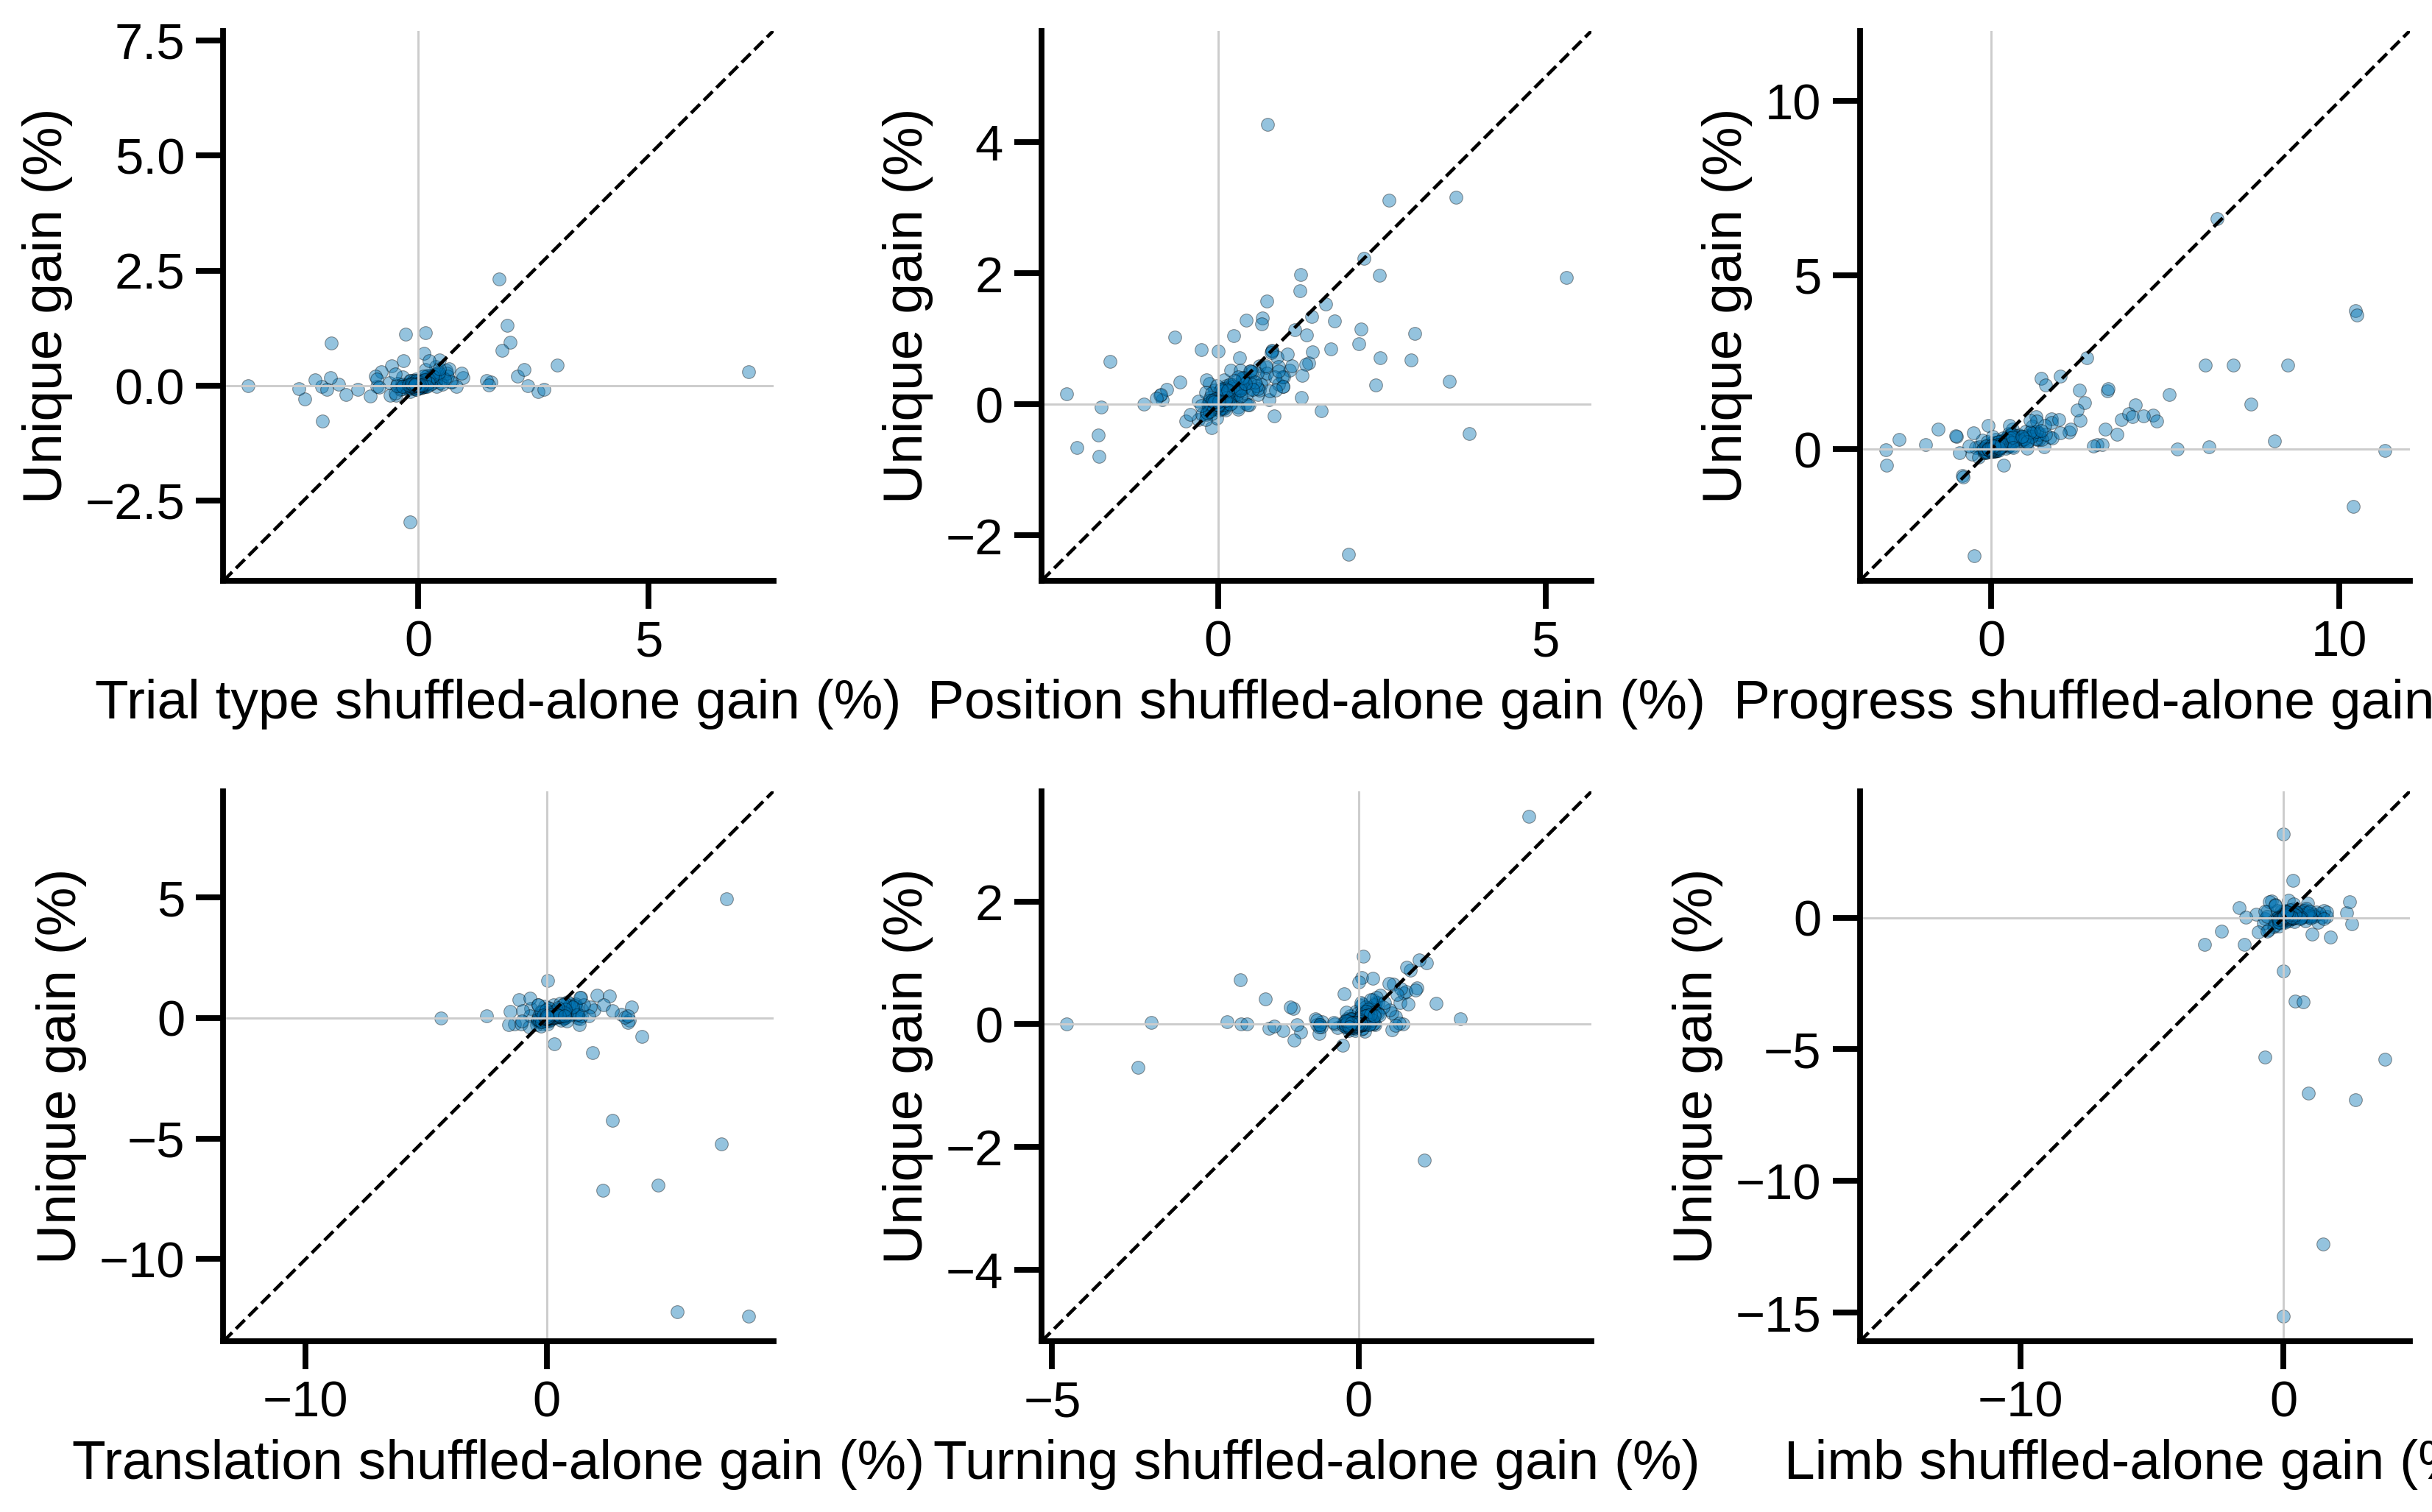

,term,n_units,median_alone_minus_unique_percent,wilcoxon_statistic,p_value,p_value_holm
0,trial_type,252,-0.037009708,12178.000000000,0.001165658,0.002331315
1,position,252,0.003370035,14603.000000000,0.248718009,0.248718009
2,progress,252,0.111606823,7647.000000000,0.000000000,0.000000000
3,translation,252,0.075261793,9708.000000000,0.000000075,0.000000298
4,turning,252,-0.055002519,9088.000000000,0.000000003,0.000000017
5,limb,252,0.040198898,10316.000000000,0.000001205,0.000003616


In [ ]:
term_labels = TERM_LABELS
n_terms = len(INDIVIDUAL_TERM_MODEL_PAIRS)
n_plot_columns = min(3, n_terms)
n_plot_rows = int(np.ceil(n_terms / n_plot_columns))
figure, axes = plt.subplots(
    n_plot_rows, n_plot_columns,
    figsize=(3.85 * n_plot_columns, 3.6 * n_plot_rows), squeeze=False,
)
pairwise_term_rows = []
for axis, term_name in zip(axes.flat, INDIVIDUAL_TERM_MODEL_PAIRS):
    alone_column, unique_column = f"{term_name}_alone", f"{term_name}_given_others"
    paired = individual_term_predictive_gains[[alone_column, unique_column]].dropna()
    x_values, y_values = 100 * paired[alone_column].to_numpy(float), 100 * paired[unique_column].to_numpy(float)
    lower, upper = min(0., x_values.min(), y_values.min()), max(0., x_values.max(), y_values.max())
    margin = .05 * (upper - lower) if upper > lower else 1.
    limits = (lower - margin, upper + margin)
    axis.scatter(x_values, y_values, s=18, color="#0072B2", alpha=.42, edgecolors="black", linewidths=.25, rasterized=True)
    axis.plot(limits, limits, "--", color="black", linewidth=1.1)
    axis.axhline(0, color=".8", linewidth=.7); axis.axvline(0, color=".8", linewidth=.7)
    axis.set(xlim=limits, ylim=limits, xlabel=f"{term_labels[term_name]} shuffled-alone gain (%)", ylabel="Unique gain (%)")
    axis.set_aspect("equal", adjustable="box")
    difference = x_values - y_values
    rounded = np.round(difference, 10)
    statistic, p_value = (0., 1.) if np.all(rounded == 0) else tuple(map(float, stats.wilcoxon(rounded, zero_method="pratt")))
    pairwise_term_rows.append({"term": term_name, "n_units": len(paired), "median_alone_minus_unique_percent": float(np.median(difference)), "wilcoxon_statistic": statistic, "p_value": p_value})
for axis in axes.flat[n_terms:]:
    axis.set_visible(False)
figure.tight_layout(); plt.show()
pairwise_term_summary = pd.DataFrame(pairwise_term_rows)
p_values = pairwise_term_summary["p_value"].to_numpy(float); order = np.argsort(p_values)
adjusted_sorted = np.maximum.accumulate((len(p_values) - np.arange(len(p_values))) * p_values[order])
adjusted = np.empty_like(adjusted_sorted); adjusted[order] = np.minimum(adjusted_sorted, 1.)
pairwise_term_summary["p_value_holm"] = adjusted
display(pairwise_term_summary)

## Term-wise overlap versus complementarity

The corrected overlap contrast is shuffled-alone gain minus unique gain. Positive values indicate information that overlaps with the full model's other predictors; negative values indicate a larger conditional (unique) gain. This is the valid term-wise replacement for the old task–movement redundancy calculation.

,term,interaction_type,n_units,percent_units
0,position,Conditional gain larger,125,49.212598425
1,position,Overlap,129,50.787401575
2,progress,Conditional gain larger,82,32.283464567
3,progress,Overlap,172,67.716535433
4,translation,Conditional gain larger,99,38.976377953
5,translation,Overlap,155,61.023622047


NameError: name 'term_labels' is not defined

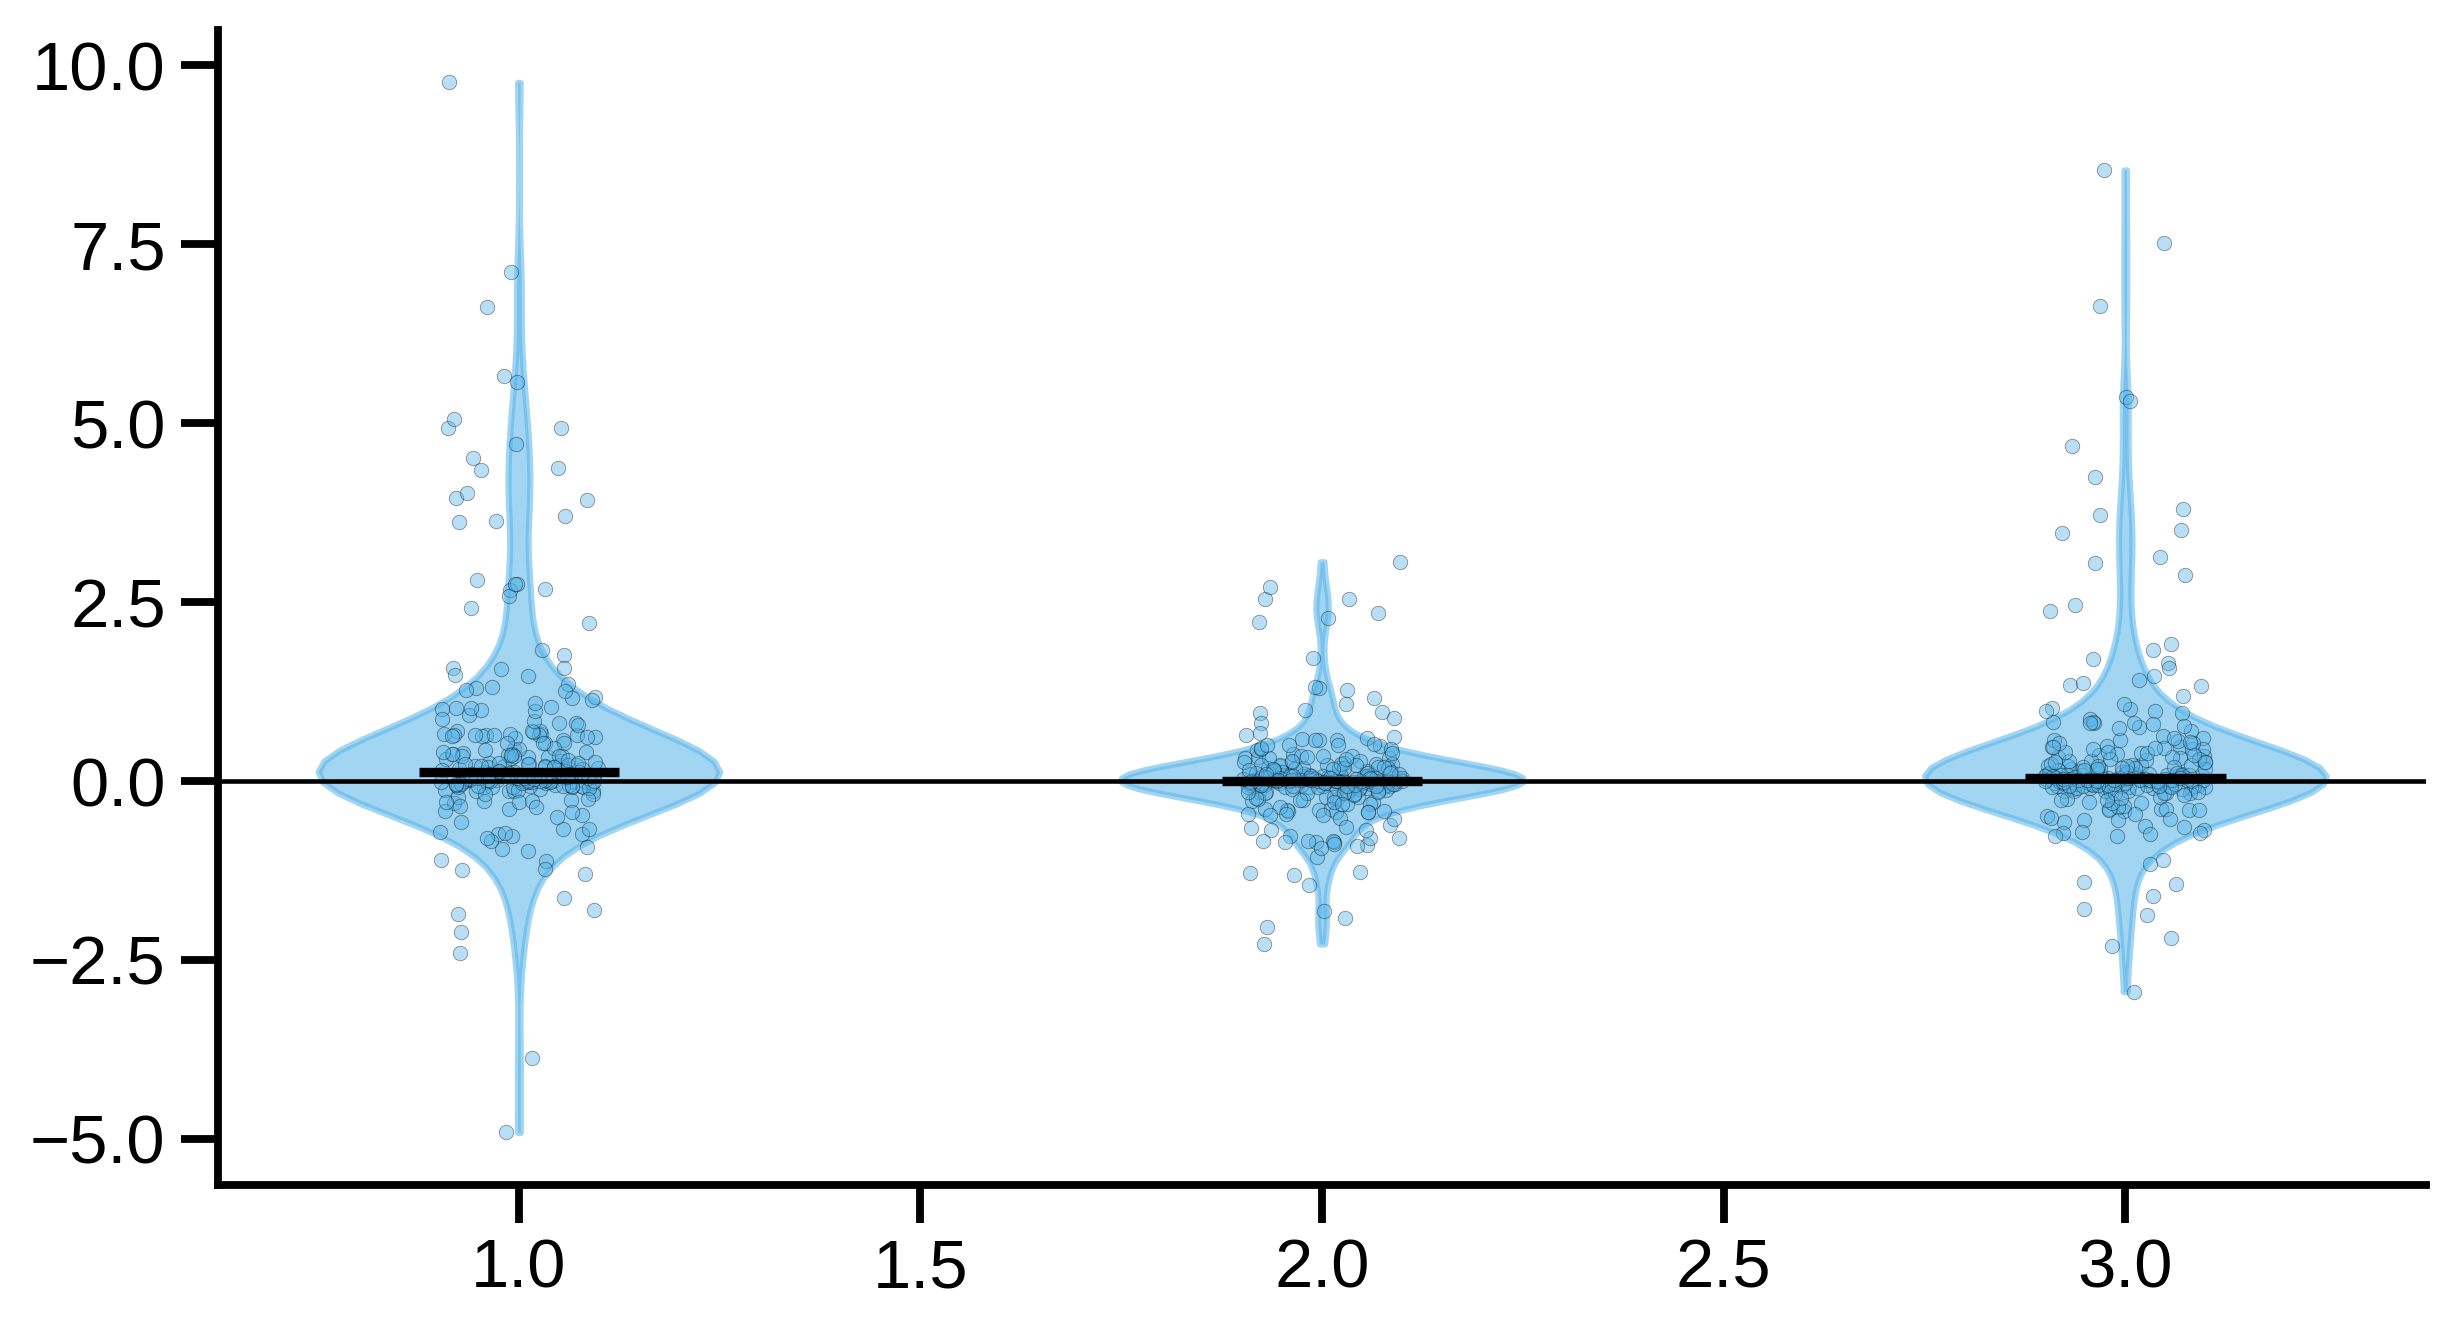

In [ ]:
TERM_OVERLAP_ADDITIVE_TOLERANCE = 0.0
term_overlap = pd.concat([
    individual_term_predictive_gains[["unit_id", "unit_index", f"{term}_alone", f"{term}_given_others"]]
    .rename(columns={f"{term}_alone": "shuffled_alone_gain", f"{term}_given_others": "unique_gain"})
    .assign(term=term, overlap_index=lambda table: table["shuffled_alone_gain"] - table["unique_gain"])
    for term in INDIVIDUAL_TERM_MODEL_PAIRS
], ignore_index=True)
term_overlap["interaction_type"] = np.select(
    [term_overlap["overlap_index"].gt(TERM_OVERLAP_ADDITIVE_TOLERANCE), term_overlap["overlap_index"].lt(-TERM_OVERLAP_ADDITIVE_TOLERANCE)],
    ["Overlap", "Conditional gain larger"], default="Equal within tolerance",
)
term_overlap_counts = term_overlap.groupby(["term", "interaction_type"], observed=True).size().rename("n_units").reset_index()
term_overlap_counts["percent_units"] = 100 * term_overlap_counts["n_units"] / len(individual_term_predictive_gains)
display(term_overlap_counts)
figure, axis = plt.subplots(figsize=(9.5, 5.0))
positions = np.arange(1, len(INDIVIDUAL_TERM_MODEL_PAIRS) + 1)
values_by_term = [100 * term_overlap.loc[term_overlap["term"].eq(term), "overlap_index"].dropna().to_numpy(float) for term in INDIVIDUAL_TERM_MODEL_PAIRS]
violins = axis.violinplot(values_by_term, positions=positions, showmeans=False, showmedians=True, showextrema=False)
for body in violins["bodies"]:
    body.set_facecolor("#56B4E9"); body.set_edgecolor("#56B4E9"); body.set_alpha(.55)
violins["cmedians"].set_color("black")
rng = np.random.default_rng(42)
for position, values in zip(positions, values_by_term):
    axis.scatter(position + rng.uniform(-.10, .10, len(values)), values, s=12, color="#56B4E9", alpha=.42, edgecolors="black", linewidths=.2)
axis.axhline(0, color="black", linewidth=1.1)
axis.set(xticks=positions, xticklabels=[term_labels[term] for term in INDIVIDUAL_TERM_MODEL_PAIRS], ylabel="Shuffled-alone − unique D² gain (%)")
axis.grid(axis="y", color=".9"); figure.tight_layout(); plt.show()

### Alone minus unique distributions

The corrected models have one alone-minus-unique distribution per term. Every finite matched unit is shown; no outliers are omitted.

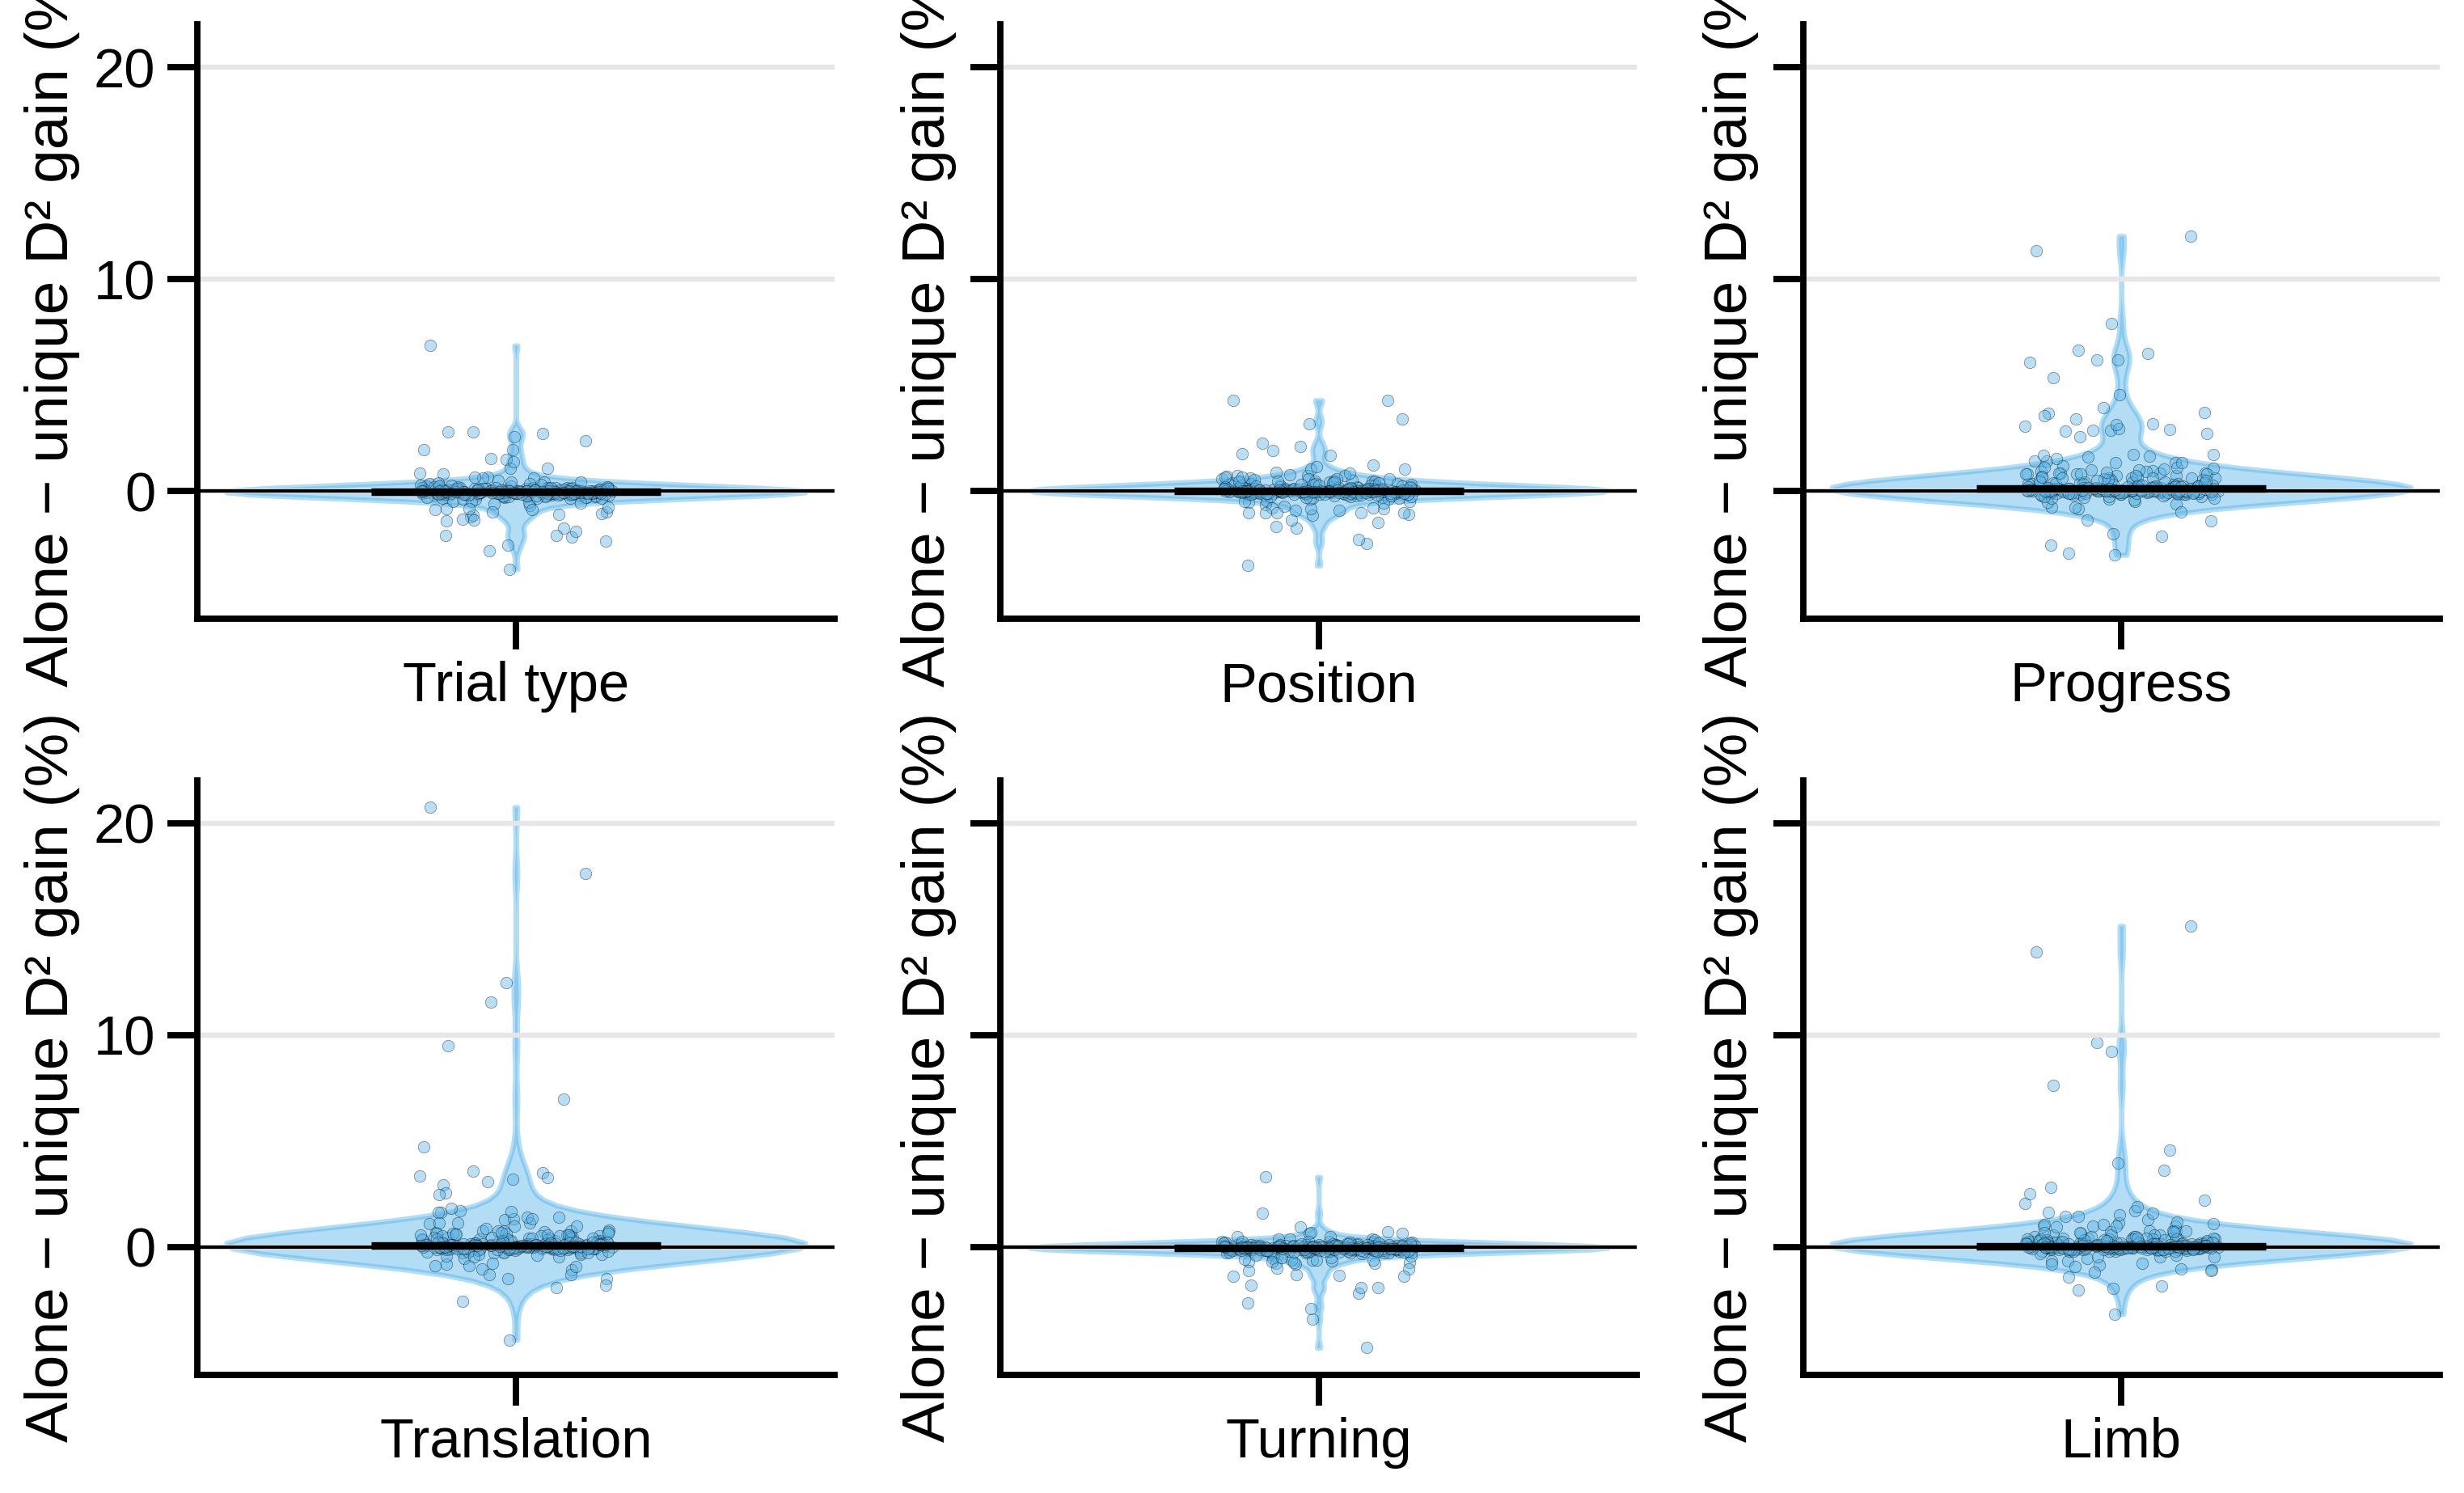

In [ ]:
figure, axes = plt.subplots(
    n_plot_rows, n_plot_columns,
    figsize=(3.5 * n_plot_columns, 3.25 * n_plot_rows),
    sharey=True, squeeze=False,
)
for axis, term_name in zip(axes.flat, INDIVIDUAL_TERM_MODEL_PAIRS):
    values = 100 * term_overlap.loc[term_overlap["term"].eq(term_name), "overlap_index"].dropna().to_numpy(float)
    violins = axis.violinplot([values], positions=[1], widths=.65, showmeans=False, showmedians=True, showextrema=False)
    for body in violins["bodies"]:
        body.set_facecolor("#56B4E9"); body.set_edgecolor("#56B4E9"); body.set_alpha(.45)
    violins["cmedians"].set_color("black")
    jitter = np.random.default_rng(42).uniform(-.11, .11, len(values))
    axis.scatter(1 + jitter, values, s=12, color="#56B4E9", alpha=.42, edgecolors="black", linewidths=.2)
    axis.axhline(0, color="black", linewidth=1.)
    axis.set(xticks=[1], xticklabels=[term_labels[term_name]], ylabel="Alone − unique D² gain (%)")
    axis.grid(axis="y", color=".9")
for axis in axes.flat[n_terms:]:
    axis.set_visible(False)
figure.tight_layout(); plt.show()